
## **Project Title: MUTUAL FUND INDUSTRY ANALYSIS**



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



* Pandas – Used for data cleaning, data processing, and data analysis.

* NumPy – Used for numerical calculations and working with numerical data.

* Matplotlib – Used to create charts and graphs for data visualization.

* Seaborn – Used to create statistical and informative visualizations.


## **Project Goal**
 * Exploratory Data Analysis (EDA) with Mutual Fund data
 * Mutual Fund Financial Analysis
 * Statistical Analysis of fund performance
 * Data Visualization using matplotlib and Seaborn
* Insight Generation from Mutual Funds data





## **Dataset Information**

| Attribute           | Value                                                                                                                                              |
| ------------------- | -------------------------------------------------------------------------------------------------------------------------------------------------- |
| **Source**          | https://indiadataportal.com/p/investments/r/amfi-amfi_monthly_report-in-mn-aaa |
| **Original Source** | INDIAN DATA PORTAL                                                                                                             |
| **Records**         | 3,115                                                                                                                                           |
| **Features**        | 14 columns                                                                                                                                         |


##**Dataset Columns**

Identification Details: id, scheme_name

Date & Time: date

Scheme Classification: scheme_type, scheme_category

Scheme Information: no_of_schemes

Investor Activity: no_of_folios

Fund Flow Information: fund_mobilized, repurchase_redemption, net_inflow_outflow

Asset Information: net_aum, avg_net_aum

Segregated Portfolio Information: no_of_segregated_portfolios, net_aum_in_segregated_portfolios

# **Features List**

* Data loading and cleaning (handling missing values, duplicates, and inconsistent values)
* Data type conversion and preprocessing
* Categorical and numerical data analysis
* Outlier detection using the IQR method
* Time-based analysis of mutual fund financial data
* Scheme type and scheme category analysis
* Investor activity analysis using number of folios
* Financial flow analysis using fund mobilization, redemption, and net inflow/outflow
* Asset analysis using Net AUM and Average Net AUM
* Correlation analysis of key financial variables
* Financial anomaly detection and identification of unusual records
* Data visualization using charts and graphs
* Comparison of financial performance across scheme types and categories
* Trend analysis of AUM and financial flows over time
* Identification of key financial patterns and insights
* Strategic conclusions and recommendations based on the analysis


In [2]:
df=pd.read_csv("/content/mutual-funds-report.csv")

In [3]:
df

,id,date,scheme_name,scheme_type,scheme_category,no_of_schemes,no_of_folios,fund_mobilized,repurchase_redemption,net_inflow_outflow,net_aum,avg_net_aum,no_of_segregated_portfolios,net_aum_in_segregated_portfolios
0,0,2019-01-04,Overnight Fund,Open ended Schemes,Income/Debt Oriented Schemes,16,21363,31583.00,31487.26,95.74,11309.75,11566.84,NaN,NaN
1,1,2019-01-04,Liquid Fund,Open ended Schemes,Income/Debt Oriented Schemes,40,1451293,1741122.88,1651344.44,89778.43,477842.96,510923.83,NaN,NaN
2,2,2019-01-04,Ultra Short Duration Fund,Open ended Schemes,Income/Debt Oriented Schemes,25,591392,21187.24,10149.98,11037.26,87144.67,86203.31,NaN,NaN
3,3,2019-01-04,Low Duration Fund,Open ended Schemes,Income/Debt Oriented Schemes,26,922455,13428.89,8515.54,4913.35,89821.94,90672.65,NaN,NaN
4,4,2019-01-04,Money Market Fund,Open ended Schemes,Income/Debt Oriented Schemes,16,284325,14309.15,7890.63,6418.52,59017.65,59200.30,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3110,3110,2023-01-09,Other Equity Schemes,Close Ended Schemes,Growth/Equity Oriented Schemes,1,1738,0.00,206.02,-206.02,114.37,273.00,0.0,0.0
3111,3111,2023-01-09,Other Schemes,Close Ended Schemes,Other Schemes,0,0,0.00,0.00,0.00,0.00,0.00,0.0,0.0
3112,3112,2023-01-09,Income/Debt Oriented Schemes,Interval Schemes,Income/Debt Oriented Schemes,12,2627,0.02,32.36,-32.34,276.81,308.96,0.0,0.0
3113,3113,2023-01-09,Growth/Equity Oriented Schemes,Interval Schemes,Growth/Equity Oriented Schemes,0,0,0.00,0.00,0.00,0.00,0.00,0.0,0.0


In [4]:
df.shape

(3115, 14)

In [5]:
print("\nColumns:")
print(df.columns.tolist())


Columns:
['id', 'date', 'scheme_name', 'scheme_type', 'scheme_category', 'no_of_schemes', 'no_of_folios', 'fund_mobilized', 'repurchase_redemption', 'net_inflow_outflow', 'net_aum', 'avg_net_aum', 'no_of_segregated_portfolios', 'net_aum_in_segregated_portfolios']


In [6]:
print("\nData Types:")
print(df.dtypes)


Data Types:
id                                    int64
date                                 object
scheme_name                          object
scheme_type                          object
scheme_category                      object
no_of_schemes                         int64
no_of_folios                          int64
fund_mobilized                      float64
repurchase_redemption               float64
net_inflow_outflow                  float64
net_aum                             float64
avg_net_aum                         float64
no_of_segregated_portfolios         float64
net_aum_in_segregated_portfolios    float64
dtype: object


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3115 entries, 0 to 3114
Data columns (total 14 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   id                                3115 non-null   int64  
 1   date                              3115 non-null   object 
 2   scheme_name                       3115 non-null   object 
 3   scheme_type                       3115 non-null   object 
 4   scheme_category                   3115 non-null   object 
 5   no_of_schemes                     3115 non-null   int64  
 6   no_of_folios                      3115 non-null   int64  
 7   fund_mobilized                    3115 non-null   float64
 8   repurchase_redemption             3115 non-null   float64
 9   net_inflow_outflow                3115 non-null   float64
 10  net_aum                           3115 non-null   float64
 11  avg_net_aum                       3115 non-null   float64
 12  no_of_

In [8]:
df.describe()

,id,no_of_schemes,no_of_folios,fund_mobilized,repurchase_redemption,net_inflow_outflow,net_aum,avg_net_aum,no_of_segregated_portfolios,net_aum_in_segregated_portfolios
count,3115.00000,3115.000000,3.115000e+03,3.115000e+03,3.115000e+03,3115.000000,3115.000000,3115.000000,2107.000000,2107.000000
mean,1557.00000,32.899839,2.518408e+06,2.026359e+04,1.979022e+04,473.369124,75805.387506,76722.931403,0.353109,6.463155
std,899.36737,67.610949,3.901334e+06,1.086546e+05,1.084230e+05,9126.246498,97879.637158,99934.678592,1.081505,34.894637
min,0.00000,0.000000,0.000000e+00,-1.085388e+04,-1.493182e+04,-157970.380000,0.000000,0.000000,0.000000,0.000000
25%,778.50000,12.000000,1.722775e+05,9.224000e+01,1.066050e+02,-166.490000,9137.100000,9022.675000,0.000000,0.000000
50%,1557.00000,22.000000,5.216060e+05,1.022550e+03,8.800500e+02,26.850000,31617.130000,31897.350000,0.000000,0.000000
75%,2335.50000,29.000000,3.522135e+06,4.081470e+03,3.183220e+03,957.000000,108359.705000,111653.280000,0.000000,0.000000
max,3114.00000,800.000000,2.478630e+07,2.143173e+06,2.097732e+06,102751.500000,777300.880000,762996.930000,10.000000,330.245700


In [9]:
df.isnull()

,id,date,scheme_name,scheme_type,scheme_category,no_of_schemes,no_of_folios,fund_mobilized,repurchase_redemption,net_inflow_outflow,net_aum,avg_net_aum,no_of_segregated_portfolios,net_aum_in_segregated_portfolios
0,False,False,False,False,False,False,False,False,False,False,False,False,True,True
1,False,False,False,False,False,False,False,False,False,False,False,False,True,True
2,False,False,False,False,False,False,False,False,False,False,False,False,True,True
3,False,False,False,False,False,False,False,False,False,False,False,False,True,True
4,False,False,False,False,False,False,False,False,False,False,False,False,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3110,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3111,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3112,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3113,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [10]:
df.isnull().sum()

,0
id,0
date,0
scheme_name,0
scheme_type,0
scheme_category,0
no_of_schemes,0
no_of_folios,0
fund_mobilized,0
repurchase_redemption,0
net_inflow_outflow,0


In [11]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage

,0
id,0.000000
date,0.000000
scheme_name,0.000000
scheme_type,0.000000
scheme_category,0.000000
no_of_schemes,0.000000
no_of_folios,0.000000
fund_mobilized,0.000000
repurchase_redemption,0.000000
net_inflow_outflow,0.000000


In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df[df['no_of_segregated_portfolios'].isnull()].head()

,id,date,scheme_name,scheme_type,scheme_category,no_of_schemes,no_of_folios,fund_mobilized,repurchase_redemption,net_inflow_outflow,net_aum,avg_net_aum,no_of_segregated_portfolios,net_aum_in_segregated_portfolios
0,0,2019-01-04,Overnight Fund,Open ended Schemes,Income/Debt Oriented Schemes,16,21363,31583.00,31487.26,95.74,11309.75,11566.84,NaN,NaN
1,1,2019-01-04,Liquid Fund,Open ended Schemes,Income/Debt Oriented Schemes,40,1451293,1741122.88,1651344.44,89778.43,477842.96,510923.83,NaN,NaN
2,2,2019-01-04,Ultra Short Duration Fund,Open ended Schemes,Income/Debt Oriented Schemes,25,591392,21187.24,10149.98,11037.26,87144.67,86203.31,NaN,NaN
3,3,2019-01-04,Low Duration Fund,Open ended Schemes,Income/Debt Oriented Schemes,26,922455,13428.89,8515.54,4913.35,89821.94,90672.65,NaN,NaN
4,4,2019-01-04,Money Market Fund,Open ended Schemes,Income/Debt Oriented Schemes,16,284325,14309.15,7890.63,6418.52,59017.65,59200.30,NaN,NaN


#**Data Cleaning**


**Change Data Types**

* The date column was initially stored as an object data type and was converted to datetime format using pd.to_datetime function for date time analysis.


In [14]:
print(df["date"].head())

0    2019-01-04
1    2019-01-04
2    2019-01-04
3    2019-01-04
4    2019-01-04
Name: date, dtype: object


In [15]:
df["date"] = pd.to_datetime(df["date"])

In [16]:
print(df["date"].dtype)

datetime64[ns]


In [17]:
print(df["scheme_type"].unique())

['Open ended Schemes' 'Close Ended Schemes' 'Interval Schemes']


In [18]:
print(df["scheme_category"].unique())

['Income/Debt Oriented Schemes' 'Growth/Equity Oriented Schemes'
 'Other Schemes' 'Hybrid Schemes' 'Solution Oriented Schemes']


In [19]:
print(df["no_of_schemes"].unique())

[ 16  40  25  26  29  17  13   2  28  21  20  22   4   7  34   0  24   6
  18  91  43  31   8  23   9  12  67 800  41  62 102  27   1  30  39  14
  19  95  42  33  35  11  76 703  84  15  10  32 107  46  93 519   5  47
  37 118  94 124 181  36 127 160  50 114 161 213 189  55  71 754  38  96
  82 607  81 111  51 101 332   3 136  92 169  87  98  44  74 740 103  89
 582  68 117 286 123 146 150  49  97 149 196 175  54 100 739  90 105 581
  78 119 289 125 163 155 203 186  99  60 116 288 152 197 183  69 765  79
 630 110 363 126 131 167 174 225 201 777  57  77 658 108 413 130 185 172
 219 195 742  86 106  45 296 177 122 208 790 669 453 121 128 162 217 192
  72  88  73  59 287 137 145 193  53 737  85 588 112 292 143  48 142 191
  83 602 306 141 140]


In [20]:
print(df.describe().T)

                                   count                           mean  \
id                                3115.0                         1557.0   
date                                3115  2021-06-13 15:31:29.566612992   
no_of_schemes                     3115.0                      32.899839   
no_of_folios                      3115.0                 2518408.001284   
fund_mobilized                    3115.0                   20263.585833   
repurchase_redemption             3115.0                   19790.216822   
net_inflow_outflow                3115.0                     473.369124   
net_aum                           3115.0                   75805.387506   
avg_net_aum                       3115.0                   76722.931403   
no_of_segregated_portfolios       2107.0                       0.353109   
net_aum_in_segregated_portfolios  2107.0                       6.463155   

                                                  min                  25%  \
id                   

####Check negative values

In [21]:
print(df[df["net_inflow_outflow"] < 0][
    ["scheme_name", "date", "net_inflow_outflow"]
].head())

             scheme_name       date  net_inflow_outflow
6   Medium Duration Fund 2019-01-04             -530.89
11      Credit Risk Fund 2019-01-04            -1253.28
13             Gilt Fund 2019-01-04              -40.86
19  Large & Mid Cap Fund 2019-01-04              -20.50
22   Dividend Yield Fund 2019-01-04              -32.03


##### Investigate the Missing Values

In [22]:
print(
    df[df["no_of_segregated_portfolios"].isnull()]
    [["scheme_type", "scheme_category"]]
    .value_counts()
)

scheme_type          scheme_category               
Open ended Schemes   Income/Debt Oriented Schemes      336
                     Growth/Equity Oriented Schemes    210
                     Hybrid Schemes                    126
Close Ended Schemes  Income/Debt Oriented Schemes       84
Open ended Schemes   Other Schemes                      84
                     Solution Oriented Schemes          42
Close Ended Schemes  Growth/Equity Oriented Schemes     42
                     Other Schemes                      21
Interval Schemes     Other Schemes                      21
                     Growth/Equity Oriented Schemes     21
                     Income/Debt Oriented Schemes       21
Name: count, dtype: int64


In [23]:
print(
    df[df["no_of_segregated_portfolios"].isnull()]
    ["scheme_category"]
    .value_counts()
)

scheme_category
Income/Debt Oriented Schemes      441
Growth/Equity Oriented Schemes    273
Hybrid Schemes                    126
Other Schemes                     126
Solution Oriented Schemes          42
Name: count, dtype: int64


####Check for text inconsistencies

In [24]:
print(df["scheme_type"].value_counts())

scheme_type
Open ended Schemes     2475
Close Ended Schemes     448
Interval Schemes        192
Name: count, dtype: int64


In [25]:
print(df["scheme_category"].value_counts())

scheme_category
Income/Debt Oriented Schemes      1344
Growth/Equity Oriented Schemes     875
Other Schemes                      384
Hybrid Schemes                     384
Solution Oriented Schemes          128
Name: count, dtype: int64


In [26]:
print(df["scheme_name"].nunique())

56


In [27]:
df["scheme_name"].unique()

array(['Overnight Fund', 'Liquid Fund', 'Ultra Short Duration Fund',
       'Low Duration Fund', 'Money Market Fund', 'Short Duration Fund',
       'Medium Duration Fund', 'Medium to Long Duration Fund',
       'Long Duration Fund', 'Dynamic Bond Fund', 'Corporate Bond Fund',
       'Credit Risk Fund', 'Banking and PSU Fund', 'Gilt Fund',
       'Gilt Fund with 10 year constant duration', 'Floater Fund',
       'Multi Cap Fund', 'Other Schemes', 'Large Cap Fund',
       'Large & Mid Cap Fund', 'Mid Cap Fund', 'Small Cap Fund',
       'Dividend Yield Fund', 'Value Fund/Contra Fund', 'Focused Fund',
       'Sectoral/Thematic Funds', 'ELSS', 'Conservative Hybrid Fund',
       'Balanced Hybrid Fund/Aggressive Hybrid Fund',
       'Dynamic Asset Allocation/Balanced Advantage',
       'Multi Asset Allocation', 'Arbitrage Fund', 'Equity Savings',
       'Retirement Fund', 'Childrens Fund', 'Index Funds', 'GOLD ETF',
       'Other ETFs', 'Fund of funds investing overseas',
       'Fixed Term P

####Remove unnecessary whitespace

In [28]:
text_columns = df.select_dtypes(include="object").columns

for col in text_columns:
    df[col] = df[col].str.strip()

In [29]:
print(df["scheme_type"].unique())

['Open ended Schemes' 'Close Ended Schemes' 'Interval Schemes']


####Check ID uniqueness

In [30]:
print("Unique IDs:", df["id"].nunique())
print("Total rows:", len(df))

Unique IDs: 3115
Total rows: 3115


In [31]:
print(df["id"].duplicated().sum())

0


In [32]:
print(df["scheme_name"].nunique())

55


####Final cleaning check

In [33]:
print("Final Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

print(df.head())


Final Shape: (3115, 14)

Missing Values:
id                                     0
date                                   0
scheme_name                            0
scheme_type                            0
scheme_category                        0
no_of_schemes                          0
no_of_folios                           0
fund_mobilized                         0
repurchase_redemption                  0
net_inflow_outflow                     0
net_aum                                0
avg_net_aum                            0
no_of_segregated_portfolios         1008
net_aum_in_segregated_portfolios    1008
dtype: int64

Duplicate Rows:
0

Data Types:
id                                           int64
date                                datetime64[ns]
scheme_name                                 object
scheme_type                                 object
scheme_category                             object
no_of_schemes                                int64
no_of_folios                      

In [34]:
print(df[df["no_of_segregated_portfolios"].isnull()]
      ["scheme_type"].value_counts())

print(df[df["no_of_segregated_portfolios"].isnull()]
      ["scheme_category"].value_counts())

print(df[df["no_of_segregated_portfolios"].isnull()]
      ["date"].value_counts().sort_index())

scheme_type
Open ended Schemes     798
Close Ended Schemes    147
Interval Schemes        63
Name: count, dtype: int64
scheme_category
Income/Debt Oriented Schemes      441
Growth/Equity Oriented Schemes    273
Hybrid Schemes                    126
Other Schemes                     126
Solution Oriented Schemes          42
Name: count, dtype: int64
date
2019-01-04    48
2019-01-05    48
2019-01-06    48
2019-01-07    48
2019-01-08    48
2019-01-09    48
2019-01-10    48
2019-01-11    48
2019-01-12    48
2020-01-01    48
2020-01-02    48
2020-01-03    48
2020-01-04    48
2020-01-05    48
2020-01-06    48
2020-01-07    48
2020-01-08    48
2020-01-09    48
2020-01-10    48
2020-01-11    48
2020-01-12    48
Name: count, dtype: int64


In [35]:
numeric_cols = [
    "no_of_schemes",
    "no_of_folios",
    "fund_mobilized",
    "repurchase_redemption",
    "net_inflow_outflow",
    "net_aum",
    "avg_net_aum"
]

print(df[numeric_cols].describe().T)

                        count          mean           std        min  \
no_of_schemes          3115.0  3.289984e+01  6.761095e+01       0.00   
no_of_folios           3115.0  2.518408e+06  3.901334e+06       0.00   
fund_mobilized         3115.0  2.026359e+04  1.086546e+05  -10853.88   
repurchase_redemption  3115.0  1.979022e+04  1.084230e+05  -14931.82   
net_inflow_outflow     3115.0  4.733691e+02  9.126246e+03 -157970.38   
net_aum                3115.0  7.580539e+04  9.787964e+04       0.00   
avg_net_aum            3115.0  7.672293e+04  9.993468e+04       0.00   

                              25%        50%          75%          max  
no_of_schemes              12.000      22.00       29.000       800.00  
no_of_folios           172277.500  521606.00  3522135.000  24786304.00  
fund_mobilized             92.240    1022.55     4081.470   2143172.74  
repurchase_redemption     106.605     880.05     3183.220   2097731.51  
net_inflow_outflow       -166.490      26.85      957.000 

In [36]:
print((df[numeric_cols] == 0).sum())

no_of_schemes            220
no_of_folios             220
fund_mobilized           519
repurchase_redemption    329
net_inflow_outflow       325
net_aum                  220
avg_net_aum              216
dtype: int64


In [37]:
print((df[numeric_cols] < 0).sum())

no_of_schemes               0
no_of_folios                0
fund_mobilized              3
repurchase_redemption       2
net_inflow_outflow       1157
net_aum                     0
avg_net_aum                 0
dtype: int64


In [38]:
print(df[df["fund_mobilized"] < 0][
    ["date", "scheme_name", "scheme_type",
     "scheme_category", "fund_mobilized"]
])

           date                             scheme_name          scheme_type  \
847  2021-01-02                      Multi Cap Fund  $$   Open ended Schemes   
1090 2021-01-01                      Multi Cap Fund  $$   Open ended Schemes   
1311 2019-01-07  Capital Protection Oriented Schemes  #  Close Ended Schemes   

                     scheme_category  fund_mobilized  
847   Growth/Equity Oriented Schemes       -10853.88  
1090  Growth/Equity Oriented Schemes       -10352.67  
1311    Income/Debt Oriented Schemes           -0.02  


In [39]:
print(df[df["repurchase_redemption"] < 0][
    ["date", "scheme_name", "scheme_type",
     "scheme_category", "repurchase_redemption"]
])

           date         scheme_name         scheme_type  \
847  2021-01-02  Multi Cap Fund  $$  Open ended Schemes   
1090 2021-01-01  Multi Cap Fund  $$  Open ended Schemes   

                     scheme_category  repurchase_redemption  
847   Growth/Equity Oriented Schemes              -14931.82  
1090  Growth/Equity Oriented Schemes              -13210.57  


In [40]:
print(df[df["fund_mobilized"] < 0]["fund_mobilized"].describe())
print(df[df["repurchase_redemption"] < 0]["repurchase_redemption"].describe())

count        3.000000
mean     -7068.856667
std       6126.919432
min     -10853.880000
25%     -10603.275000
50%     -10352.670000
75%      -5176.345000
max         -0.020000
Name: fund_mobilized, dtype: float64
count        2.000000
mean    -14071.195000
std       1217.107547
min     -14931.820000
25%     -14501.507500
50%     -14071.195000
75%     -13640.882500
max     -13210.570000
Name: repurchase_redemption, dtype: float64


####Net inflow/outflow ≈ Fund Mobilized − Repurchase/Redemption

In [41]:
df["calculated_net_flow"] = (
    df["fund_mobilized"] - df["repurchase_redemption"]
)

df["flow_difference"] = (
    df["net_inflow_outflow"] - df["calculated_net_flow"]
)

print(df["flow_difference"].describe())

count    3.115000e+03
mean     1.123596e-04
std      4.542692e-03
min     -1.000000e-02
25%     -2.842171e-14
50%      0.000000e+00
75%      5.684342e-14
max      1.000000e-02
Name: flow_difference, dtype: float64


In [42]:
df.drop(columns=["calculated_net_flow", "flow_difference"], inplace=True)

####Create an anomaly flag:

In [43]:
df["financial_anomaly"] = (
    (df["fund_mobilized"] < 0) |
    (df["repurchase_redemption"] < 0)
)

print(df["financial_anomaly"].value_counts())

financial_anomaly
False    3112
True        3
Name: count, dtype: int64


####Fix scheme_type

In [44]:
print(df["scheme_type"].value_counts())

scheme_type
Open ended Schemes     2475
Close Ended Schemes     448
Interval Schemes        192
Name: count, dtype: int64


In [45]:
print(df[df["scheme_name"].str.contains(r"[$#]", regex=True)][["scheme_name", "scheme_type", "scheme_category"]])

                                 scheme_name          scheme_type  \
337   Capital Protection Oriented Schemes  #  Close Ended Schemes   
435                       Fixed Term Plan ##  Close Ended Schemes   
580   Capital Protection Oriented Schemes  #  Close Ended Schemes   
847                       Multi Cap Fund  $$   Open ended Schemes   
1090                      Multi Cap Fund  $$   Open ended Schemes   
1311  Capital Protection Oriented Schemes  #  Close Ended Schemes   
2425  Capital Protection Oriented Schemes  #  Close Ended Schemes   
2670  Capital Protection Oriented Schemes  #  Close Ended Schemes   
2911  Capital Protection Oriented Schemes  #  Close Ended Schemes   

                     scheme_category  
337     Income/Debt Oriented Schemes  
435     Income/Debt Oriented Schemes  
580     Income/Debt Oriented Schemes  
847   Growth/Equity Oriented Schemes  
1090  Growth/Equity Oriented Schemes  
1311    Income/Debt Oriented Schemes  
2425    Income/Debt Oriented Schemes

In [46]:
print(df["scheme_category"].value_counts())

scheme_category
Income/Debt Oriented Schemes      1344
Growth/Equity Oriented Schemes     875
Other Schemes                      384
Hybrid Schemes                     384
Solution Oriented Schemes          128
Name: count, dtype: int64


In [47]:
print(df["scheme_category"].unique())

['Income/Debt Oriented Schemes' 'Growth/Equity Oriented Schemes'
 'Other Schemes' 'Hybrid Schemes' 'Solution Oriented Schemes']


I wouldn't remove the 3 anomalous rows automatically. Since this is financial data, changing or deleting source observations without knowing what the symbols mean could make the analysis less defensible.


we can document them as data-quality anomalies and decide whether to exclude them from specific analyses if necessary.

In [48]:
print("Unique IDs:", df["id"].nunique())
print("Total rows:", len(df))
print("Duplicate IDs:", df["id"].duplicated().sum())

Unique IDs: 3115
Total rows: 3115
Duplicate IDs: 0


#### **Checking Outliers with the IQR (Interquartile Range) Method**

In [49]:
numeric_cols = df.select_dtypes(include="number").columns.drop("id")

print(numeric_cols)

Index(['no_of_schemes', 'no_of_folios', 'fund_mobilized',
       'repurchase_redemption', 'net_inflow_outflow', 'net_aum', 'avg_net_aum',
       'no_of_segregated_portfolios', 'net_aum_in_segregated_portfolios'],
      dtype='object')


Calculate IQR and count outliers

In [50]:
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    print(f"{col}: {len(outliers)} outliers")

no_of_schemes: 256 outliers
no_of_folios: 318 outliers
fund_mobilized: 409 outliers
repurchase_redemption: 420 outliers
net_inflow_outflow: 643 outliers
net_aum: 161 outliers
avg_net_aum: 150 outliers
no_of_segregated_portfolios: 306 outliers
net_aum_in_segregated_portfolios: 198 outliers


The IQR method flags unusual values; it does not prove that they are errors.

For this mutual-funds dataset, high values in things like:

no_of_folios
fund_mobilized
net_aum
net_inflow_outflow

can naturally occur because some schemes are much larger than others.

For example, net_inflow_outflow has 643 IQR outliers, but we already know that negative values can legitimately represent money flowing out of funds.

Let's inspect the actual boundaries and a few outlier records rather than deleting anything.

Run this for net_inflow_outflow first:

In [51]:
Q1 = df["net_inflow_outflow"].quantile(0.25)
Q3 = df["net_inflow_outflow"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: -166.49
Q3: 957.0
IQR: 1123.49
Lower Bound: -1851.7250000000001
Upper Bound: 2642.235


In [52]:
outliers = df[
    (df["net_inflow_outflow"] < lower_bound) |
    (df["net_inflow_outflow"] > upper_bound)
]

print(outliers[
    ["date", "scheme_name", "scheme_category", "net_inflow_outflow"]
].head(20))

         date                                  scheme_name  \
1  2019-01-04                                  Liquid Fund   
2  2019-01-04                    Ultra Short Duration Fund   
3  2019-01-04                            Low Duration Fund   
4  2019-01-04                            Money Market Fund   
5  2019-01-04                          Short Duration Fund   
10 2019-01-04                          Corporate Bond Fund   
12 2019-01-04                         Banking and PSU Fund   
28 2019-01-04  Balanced Hybrid Fund/Aggressive Hybrid Fund   
37 2019-01-04                                   Other ETFs   
39 2019-01-04                              Fixed Term Plan   
50 2020-01-04                                  Liquid Fund   
51 2020-01-04                    Ultra Short Duration Fund   
52 2020-01-04                            Low Duration Fund   
54 2020-01-04                          Short Duration Fund   
55 2020-01-04                         Medium Duration Fund   
59 2020-

Yes — this confirms that the IQR method is flagging extreme financial values, not necessarily incorrect data.

For example, Liquid Fund has 89,778.43, which is far above the IQR upper bound. But that can represent a genuinely large net inflow rather than a data-entry error.

In essence IQR outliers were identified but retained because extreme values may represent genuine differences in fund flows and financial activity.

Let's see whether the outliers are concentrated in particular years. Run:

In [53]:
outliers = df[
    (df["net_inflow_outflow"] < lower_bound) |
    (df["net_inflow_outflow"] > upper_bound)
].copy()

outliers["year"] = outliers["date"].dt.year

print(outliers["year"].value_counts().sort_index())

year
2019     78
2020    121
2021    132
2022    127
2023    102
2024     83
Name: count, dtype: int64


Outliers were identified using the IQR method. Since extreme financial values can represent genuine fund inflows, outflows, and differences in scheme size, the identified outliers were retained and not removed.

In [54]:
df.describe()

,id,date,no_of_schemes,no_of_folios,fund_mobilized,repurchase_redemption,net_inflow_outflow,net_aum,avg_net_aum,no_of_segregated_portfolios,net_aum_in_segregated_portfolios
count,3115.00000,3115,3115.000000,3.115000e+03,3.115000e+03,3.115000e+03,3115.000000,3115.000000,3115.000000,2107.000000,2107.000000
mean,1557.00000,2021-06-13 15:31:29.566612992,32.899839,2.518408e+06,2.026359e+04,1.979022e+04,473.369124,75805.387506,76722.931403,0.353109,6.463155
min,0.00000,2019-01-04 00:00:00,0.000000,0.000000e+00,-1.085388e+04,-1.493182e+04,-157970.380000,0.000000,0.000000,0.000000,0.000000
25%,778.50000,2020-01-08 00:00:00,12.000000,1.722775e+05,9.224000e+01,1.066050e+02,-166.490000,9137.100000,9022.675000,0.000000,0.000000
50%,1557.00000,2021-01-12 00:00:00,22.000000,5.216060e+05,1.022550e+03,8.800500e+02,26.850000,31617.130000,31897.350000,0.000000,0.000000
75%,2335.50000,2023-01-04 00:00:00,29.000000,3.522135e+06,4.081470e+03,3.183220e+03,957.000000,108359.705000,111653.280000,0.000000,0.000000
max,3114.00000,2024-01-07 00:00:00,800.000000,2.478630e+07,2.143173e+06,2.097732e+06,102751.500000,777300.880000,762996.930000,10.000000,330.245700
std,899.36737,NaN,67.610949,3.901334e+06,1.086546e+05,1.084230e+05,9126.246498,97879.637158,99934.678592,1.081505,34.894637


In [55]:
text_cols = df.select_dtypes(include="object").columns

for col in text_cols:
    print(f"\n{col}:")
    print(df[col].astype(str).str.strip().nunique(), "unique values")


scheme_name:
55 unique values

scheme_type:
3 unique values

scheme_category:
5 unique values


In [56]:
for col in text_cols:
    df[col] = df[col].str.strip()

In [57]:
for col in text_cols:
    print(col, ":", (df[col] == "").sum())

scheme_name : 0
scheme_type : 0
scheme_category : 0


In [58]:
print(df.isnull().sum())

id                                     0
date                                   0
scheme_name                            0
scheme_type                            0
scheme_category                        0
no_of_schemes                          0
no_of_folios                           0
fund_mobilized                         0
repurchase_redemption                  0
net_inflow_outflow                     0
net_aum                                0
avg_net_aum                            0
no_of_segregated_portfolios         1008
net_aum_in_segregated_portfolios    1008
financial_anomaly                      0
dtype: int64


In [59]:
print(df["financial_anomaly"].value_counts(dropna=False))

financial_anomaly
False    3112
True        3
Name: count, dtype: int64


In [60]:
df[df['financial_anomaly'] == True]

,id,date,scheme_name,scheme_type,scheme_category,no_of_schemes,no_of_folios,fund_mobilized,repurchase_redemption,net_inflow_outflow,net_aum,avg_net_aum,no_of_segregated_portfolios,net_aum_in_segregated_portfolios,financial_anomaly
847,842,2021-01-02,Multi Cap Fund $$,Open ended Schemes,Growth/Equity Oriented Schemes,10,1391762,-10853.88,-14931.82,4077.94,20158.18,20017.23,0.0,0.0,True
1090,1086,2021-01-01,Multi Cap Fund $$,Open ended Schemes,Growth/Equity Oriented Schemes,19,5375283,-10352.67,-13210.57,2857.90,87826.70,92144.71,0.0,0.0,True
1311,1305,2019-01-07,Capital Protection Oriented Schemes #,Close Ended Schemes,Income/Debt Oriented Schemes,39,149046,-0.02,48.01,-48.03,5624.67,5719.05,NaN,NaN,True


Financial Anomaly Detection: The analysis identified 3 financial anomalies out of 3,115 records. These records showed unusual patterns in fund mobilization, repurchase/redemption, net inflow/outflow, and, in one case, missing segregated portfolio information.

**Checking Missing Values**

In [61]:
missing_seg = df[
    df["no_of_segregated_portfolios"].isna()
]

print("Missing records:", len(missing_seg))

print("\nScheme Type:")
print(missing_seg["scheme_type"].value_counts(dropna=False))

print("\nScheme Category:")
print(missing_seg["scheme_category"].value_counts(dropna=False))

Missing records: 1008

Scheme Type:
scheme_type
Open ended Schemes     798
Close Ended Schemes    147
Interval Schemes        63
Name: count, dtype: int64

Scheme Category:
scheme_category
Income/Debt Oriented Schemes      441
Growth/Equity Oriented Schemes    273
Hybrid Schemes                    126
Other Schemes                     126
Solution Oriented Schemes          42
Name: count, dtype: int64


In [62]:
print(
    missing_seg[
        ["scheme_name", "scheme_type", "scheme_category",
         "no_of_segregated_portfolios",
         "net_aum_in_segregated_portfolios"]
    ].head(20)
)

                                 scheme_name         scheme_type  \
0                             Overnight Fund  Open ended Schemes   
1                                Liquid Fund  Open ended Schemes   
2                  Ultra Short Duration Fund  Open ended Schemes   
3                          Low Duration Fund  Open ended Schemes   
4                          Money Market Fund  Open ended Schemes   
5                        Short Duration Fund  Open ended Schemes   
6                       Medium Duration Fund  Open ended Schemes   
7               Medium to Long Duration Fund  Open ended Schemes   
8                         Long Duration Fund  Open ended Schemes   
9                          Dynamic Bond Fund  Open ended Schemes   
10                       Corporate Bond Fund  Open ended Schemes   
11                          Credit Risk Fund  Open ended Schemes   
12                      Banking and PSU Fund  Open ended Schemes   
13                                 Gilt Fund  Op

In [63]:
# Check whether missing values occur simultaneously
print(
    df["no_of_segregated_portfolios"].isna().equals(
        df["net_aum_in_segregated_portfolios"].isna()
    )
)

True


In [64]:
missing_seg.groupby(
    ["scheme_type", "scheme_category"]
).size()

scheme_type          scheme_category               
Close Ended Schemes  Growth/Equity Oriented Schemes     42
                     Income/Debt Oriented Schemes       84
                     Other Schemes                      21
Interval Schemes     Growth/Equity Oriented Schemes     21
                     Income/Debt Oriented Schemes       21
                     Other Schemes                      21
Open ended Schemes   Growth/Equity Oriented Schemes    210
                     Hybrid Schemes                    126
                     Income/Debt Oriented Schemes      336
                     Other Schemes                      84
                     Solution Oriented Schemes          42
dtype: int64

In [65]:
print(
    df.loc[
        df["no_of_segregated_portfolios"].isna(),
        ["scheme_name", "scheme_type", "scheme_category"]
    ].head(30).to_string(index=False)
)

                                scheme_name        scheme_type                scheme_category
                             Overnight Fund Open ended Schemes   Income/Debt Oriented Schemes
                                Liquid Fund Open ended Schemes   Income/Debt Oriented Schemes
                  Ultra Short Duration Fund Open ended Schemes   Income/Debt Oriented Schemes
                          Low Duration Fund Open ended Schemes   Income/Debt Oriented Schemes
                          Money Market Fund Open ended Schemes   Income/Debt Oriented Schemes
                        Short Duration Fund Open ended Schemes   Income/Debt Oriented Schemes
                       Medium Duration Fund Open ended Schemes   Income/Debt Oriented Schemes
               Medium to Long Duration Fund Open ended Schemes   Income/Debt Oriented Schemes
                         Long Duration Fund Open ended Schemes   Income/Debt Oriented Schemes
                          Dynamic Bond Fund Open ended Schem

In [66]:
print(
    df.loc[
        df["no_of_segregated_portfolios"].notna(),
        [
            "scheme_name",
            "scheme_type",
            "scheme_category",
            "no_of_segregated_portfolios",
            "net_aum_in_segregated_portfolios"
        ]
    ].head(20).to_string(index=False)
)

                             scheme_name         scheme_type                scheme_category  no_of_segregated_portfolios  net_aum_in_segregated_portfolios
                           Other Schemes Close Ended Schemes                  Other Schemes                          0.0                            0.0000
                           Other Schemes Close Ended Schemes                  Other Schemes                          0.0                            0.0000
                          Overnight Fund  Open ended Schemes   Income/Debt Oriented Schemes                          0.0                            0.0000
                             Liquid Fund  Open ended Schemes   Income/Debt Oriented Schemes                          0.0                            0.0000
               Ultra Short Duration Fund  Open ended Schemes   Income/Debt Oriented Schemes                          0.0                            0.0000
                       Low Duration Fund  Open ended Schemes   Income/

The two segregated portfolio variables contain 1,008 missing records each, and their missingness occurs simultaneously. Since these variables are specifically related to segregated portfolios, replacing the missing values with zero without confirming their meaning could introduce assumptions. Therefore, the missing values were retained as NaN.

### **Exploratory Data Analysis (EDA) and Visualization**

Exploratory Data Analysis is performed to understand the distribution of mutual fund schemes, scheme types, scheme categories, investor participation, and key financial variables before conducting detailed financial and statistical analysis.

####**Checking the distribution of Scheme Types**

In [67]:
scheme_type_counts = df["scheme_type"].value_counts()

print(scheme_type_counts)

scheme_type
Open ended Schemes     2475
Close Ended Schemes     448
Interval Schemes        192
Name: count, dtype: int64


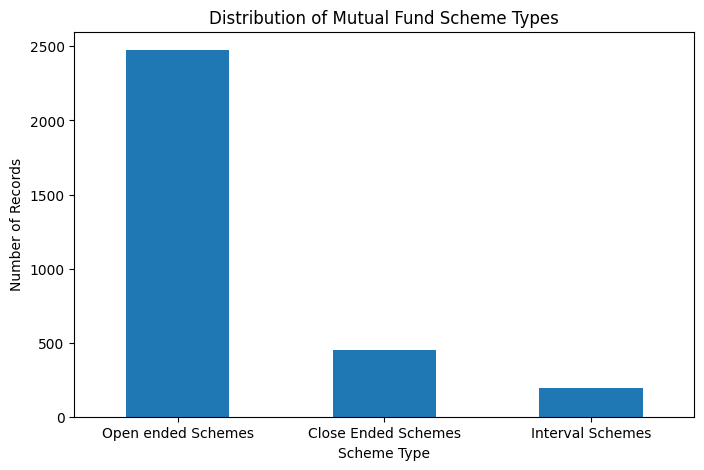

In [68]:
plt.figure(figsize=(8,5))

scheme_type_counts.plot(kind="bar")

plt.title("Distribution of Mutual Fund Scheme Types")
plt.xlabel("Scheme Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)

plt.show()

Insight: Open-ended schemes dominate the dataset with 2,475 records, while close-ended and interval schemes account for considerably fewer records. This indicates that the dataset is primarily represented by open-ended mutual fund schemes.

**Analysing Scheme Categories**

In [69]:
scheme_category_counts = df["scheme_category"].value_counts()

print(scheme_category_counts)

scheme_category
Income/Debt Oriented Schemes      1344
Growth/Equity Oriented Schemes     875
Other Schemes                      384
Hybrid Schemes                     384
Solution Oriented Schemes          128
Name: count, dtype: int64


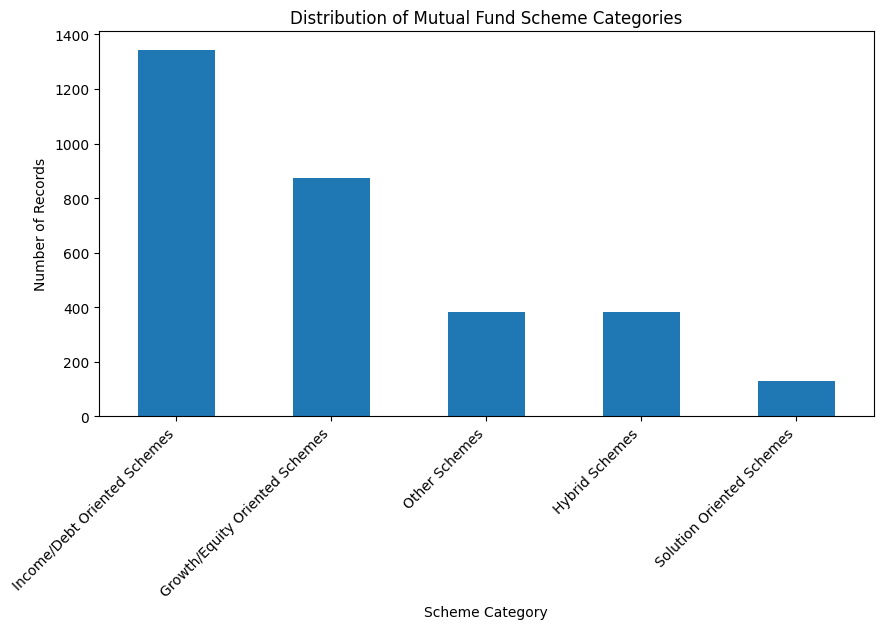

In [70]:
plt.figure(figsize=(10,5))

scheme_category_counts.plot(kind="bar")

plt.title("Distribution of Mutual Fund Scheme Categories")
plt.xlabel("Scheme Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")

plt.show()

Insight: Income/Debt Oriented Schemes have the largest representation with 1,344 records, followed by Growth/Equity Oriented Schemes with 875 records. Solution Oriented Schemes have the smallest representation with 128 records.

**Analysing the Number of Schemes**

In [71]:
print(df["no_of_schemes"].describe())

count    3115.000000
mean       32.899839
std        67.610949
min         0.000000
25%        12.000000
50%        22.000000
75%        29.000000
max       800.000000
Name: no_of_schemes, dtype: float64


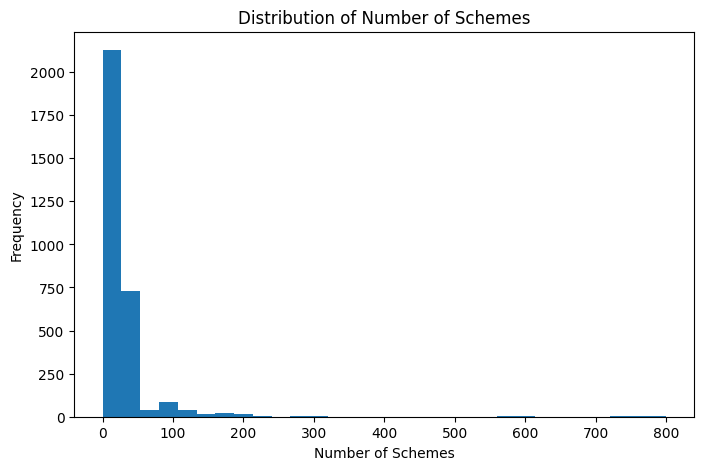

In [72]:
plt.figure(figsize=(8,5))

plt.hist(df["no_of_schemes"].dropna(), bins=30)

plt.title("Distribution of Number of Schemes")
plt.xlabel("Number of Schemes")
plt.ylabel("Frequency")

plt.show()

Insight: The number of schemes is right-skewed, with a mean of 32.90 compared with a median of 22. Most observations contain relatively fewer schemes, while a small number of observations have substantially higher values, with a maximum of 800 schemes.

**Analysing Investor** **Participation**

In [73]:
print(df["no_of_folios"].describe())

count    3.115000e+03
mean     2.518408e+06
std      3.901334e+06
min      0.000000e+00
25%      1.722775e+05
50%      5.216060e+05
75%      3.522135e+06
max      2.478630e+07
Name: no_of_folios, dtype: float64


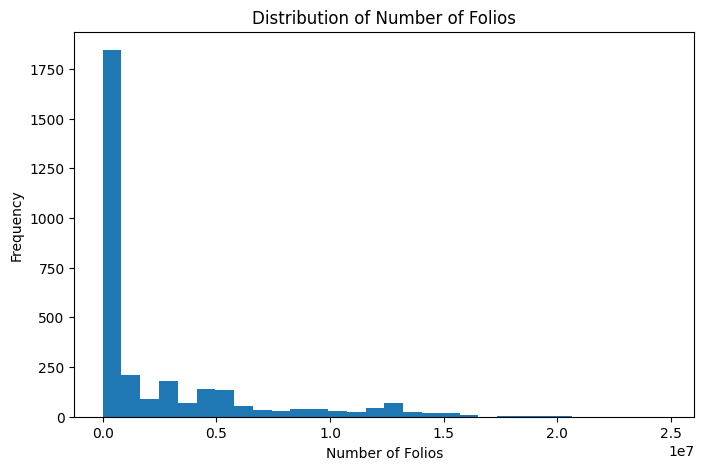

In [74]:
plt.figure(figsize=(8,5))

plt.hist(df["no_of_folios"].dropna(), bins=30)

plt.title("Distribution of Number of Folios")
plt.xlabel("Number of Folios")
plt.ylabel("Frequency")

plt.show()

Insight: Investor participation is highly right-skewed. The median number of folios is approximately 521,606, while the mean is much higher at approximately 2.52 million, indicating that a relatively small number of schemes have exceptionally high investor participation.

**Comparing Investor Participation by Scheme Category**

In [75]:
folios_by_category = (
    df.groupby("scheme_category")["no_of_folios"]
      .sum()
      .sort_values(ascending=False)
)

print(folios_by_category)

scheme_category
Growth/Equity Oriented Schemes    5399301356
Other Schemes                      902069434
Hybrid Schemes                     704516880
Income/Debt Oriented Schemes       482014710
Solution Oriented Schemes          356938544
Name: no_of_folios, dtype: int64


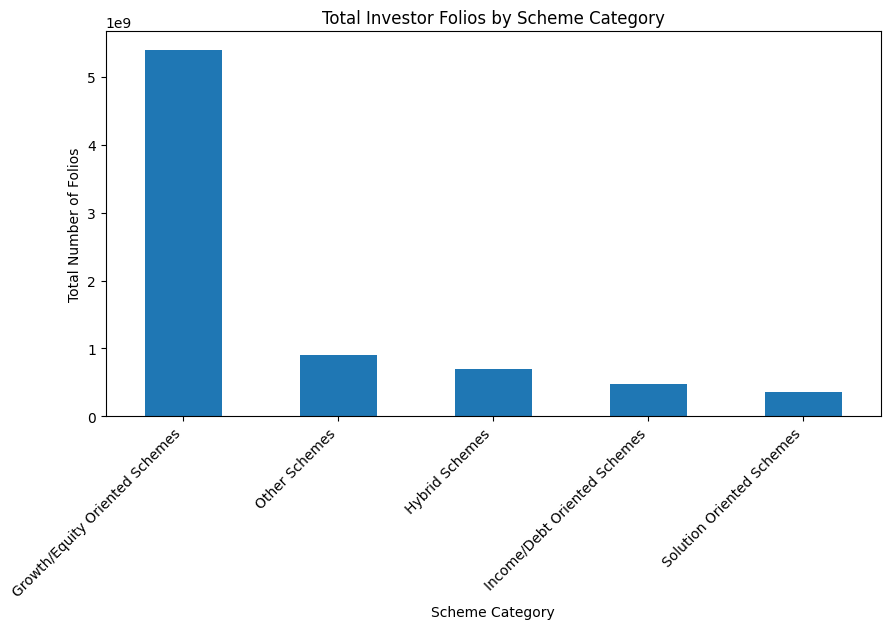

In [76]:
plt.figure(figsize=(10,5))

folios_by_category.plot(kind="bar")

plt.title("Total Investor Folios by Scheme Category")
plt.xlabel("Scheme Category")
plt.ylabel("Total Number of Folios")
plt.xticks(rotation=45, ha="right")

plt.show()

Insight: Growth/Equity Oriented Schemes have the highest total investor folios at approximately 5.40 billion, substantially exceeding all other categories. This indicates that the Growth/Equity category has the largest recorded investor participation in this dataset.

**Analysing Net AUM by Scheme Category**

In [77]:
aum_by_category = (
    df.groupby("scheme_category")["net_aum"]
      .sum()
      .sort_values(ascending=False)
)

print(aum_by_category)

scheme_category
Income/Debt Oriented Schemes      87775440.84
Growth/Equity Oriented Schemes    85874665.40
Other Schemes                     31383968.88
Hybrid Schemes                    29274348.10
Solution Oriented Schemes          1825358.86
Name: net_aum, dtype: float64


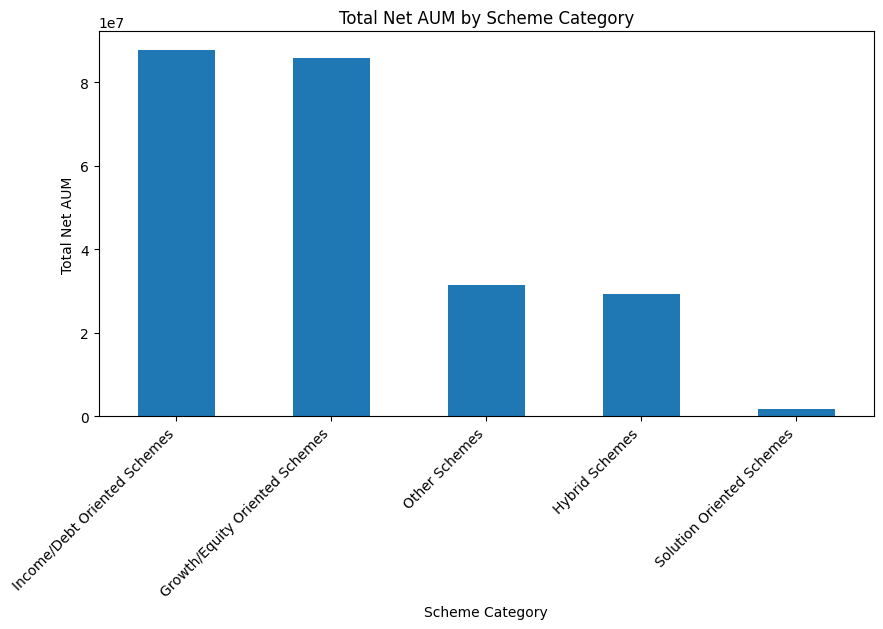

In [78]:
plt.figure(figsize=(10,5))

aum_by_category.plot(kind="bar")

plt.title("Total Net AUM by Scheme Category")
plt.xlabel("Scheme Category")
plt.ylabel("Total Net AUM")
plt.xticks(rotation=45, ha="right")

plt.show()

Insight: Income/Debt Oriented Schemes have the highest total Net AUM at approximately 87.78 million, closely followed by Growth/Equity Oriented Schemes at approximately 85.87 million. Despite Growth/Equity having substantially more recorded folios, Income/Debt has slightly higher total AUM.

**Analysing Net Inflow/Outflow**

In [79]:
print(df["net_inflow_outflow"].describe())

count      3115.000000
mean        473.369124
std        9126.246498
min     -157970.380000
25%        -166.490000
50%          26.850000
75%         957.000000
max      102751.500000
Name: net_inflow_outflow, dtype: float64


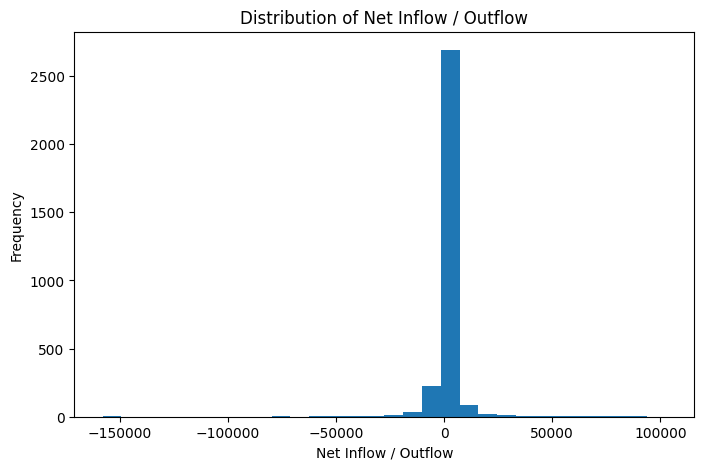

In [80]:
plt.figure(figsize=(8,5))

plt.hist(df["net_inflow_outflow"].dropna(), bins=30)

plt.title("Distribution of Net Inflow / Outflow")
plt.xlabel("Net Inflow / Outflow")
plt.ylabel("Frequency")

plt.show()

Insight: Net inflow/outflow is highly dispersed, with a median of 26.85 compared with a mean of 473.37. The wide range from -157,970.38 to 102,751.50 indicates substantial variation in fund flows, with both significant inflows and outflows present in the dataset.

**Comparing Net Inflow/Outflow by Category**

In [81]:
inflow_by_category = (
    df.groupby("scheme_category")["net_inflow_outflow"]
      .sum()
      .sort_values(ascending=False)
)

print(inflow_by_category)

scheme_category
Growth/Equity Oriented Schemes    653402.97
Other Schemes                     540091.23
Hybrid Schemes                    258803.03
Income/Debt Oriented Schemes       11708.75
Solution Oriented Schemes          10538.84
Name: net_inflow_outflow, dtype: float64


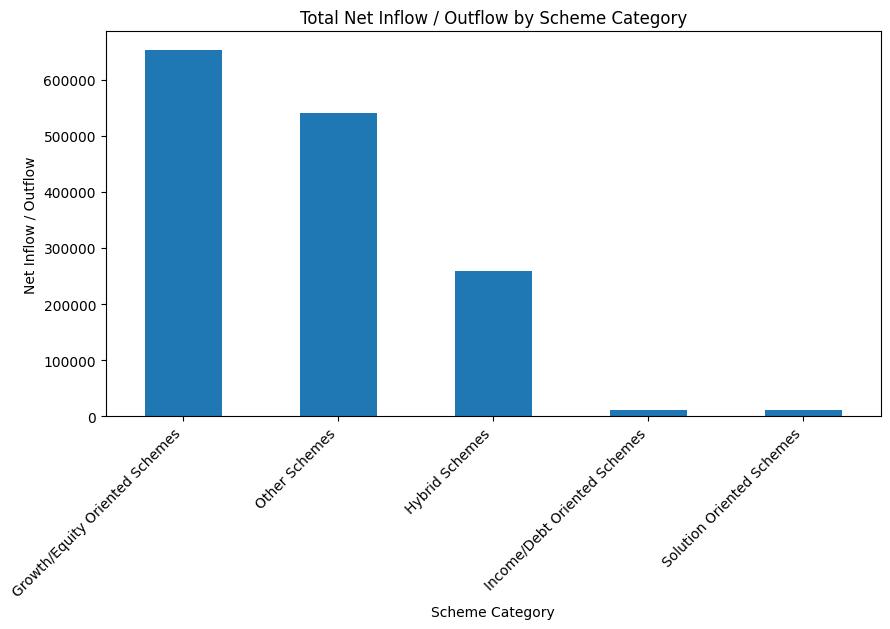

In [82]:
plt.figure(figsize=(10,5))

inflow_by_category.plot(kind="bar")

plt.title("Total Net Inflow / Outflow by Scheme Category")
plt.xlabel("Scheme Category")
plt.ylabel("Net Inflow / Outflow")
plt.xticks(rotation=45, ha="right")

plt.show()

Insight: Growth/Equity Oriented Schemes recorded the highest total net inflow of approximately 653,403, followed by Other Schemes at approximately 540,091. Hybrid Schemes also recorded a positive net inflow, while Income/Debt and Solution Oriented Schemes recorded comparatively small positive net inflows.

**Fund Mobilized vs Repurchase/Redemption by Category**

In [83]:
flow_comparison = df.groupby("scheme_category")[
    ["fund_mobilized", "repurchase_redemption"]
].sum().sort_values("fund_mobilized", ascending=False)

flow_comparison

,fund_mobilized,repurchase_redemption
scheme_category,,
Income/Debt Oriented Schemes,58723619.24,58711910.75
Growth/Equity Oriented Schemes,2024982.13,1371579.10
Hybrid Schemes,1239037.36,980234.27
Other Schemes,1111431.71,571340.57
Solution Oriented Schemes,21999.43,11460.71


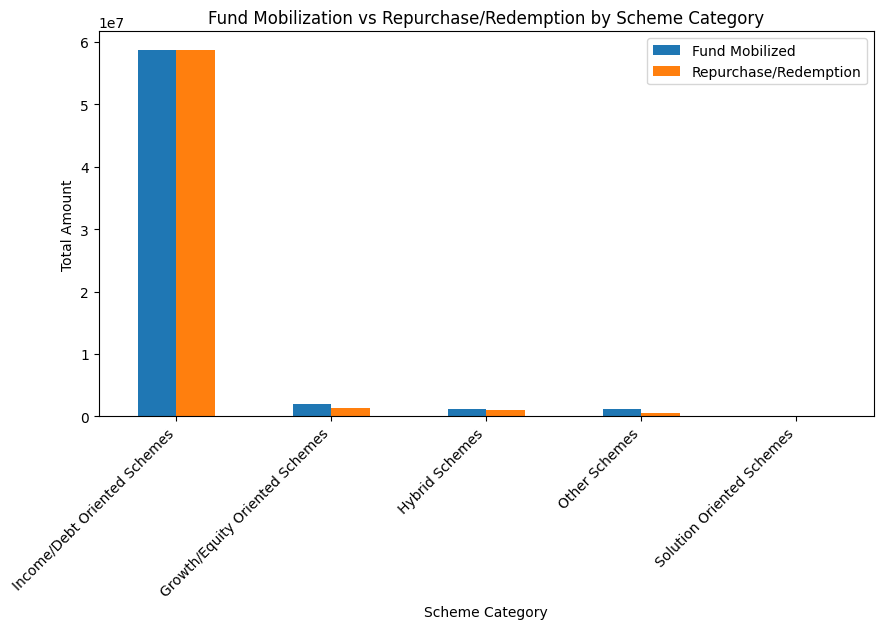

In [84]:
flow_comparison.plot(kind="bar", figsize=(10,5))

plt.title("Fund Mobilization vs Repurchase/Redemption by Scheme Category")
plt.xlabel("Scheme Category")
plt.ylabel("Total Amount")
plt.xticks(rotation=45, ha="right")
plt.legend(["Fund Mobilized", "Repurchase/Redemption"])

plt.show()

Income/Debt Oriented Schemes recorded the highest fund mobilization at approximately 58.72 million, closely followed by repurchase/redemption of 58.71 million. Growth/Equity Oriented Schemes ranked second in both fund mobilization and repurchase/redemption. Overall, fund mobilization and redemption values are relatively close within each category, indicating that a large portion of the mobilized funds was offset by repurchases/redemptions.(mobilization remained higher than redemption across all categories)

####**Correlation** **Heatmap**

In [85]:
#Give me only the numerical columns from my dataset.
numeric_cols = df.select_dtypes(include="number")

In [86]:
#calculate the correlation between those numerical columns.
correlation_matrix = numeric_cols.corr()

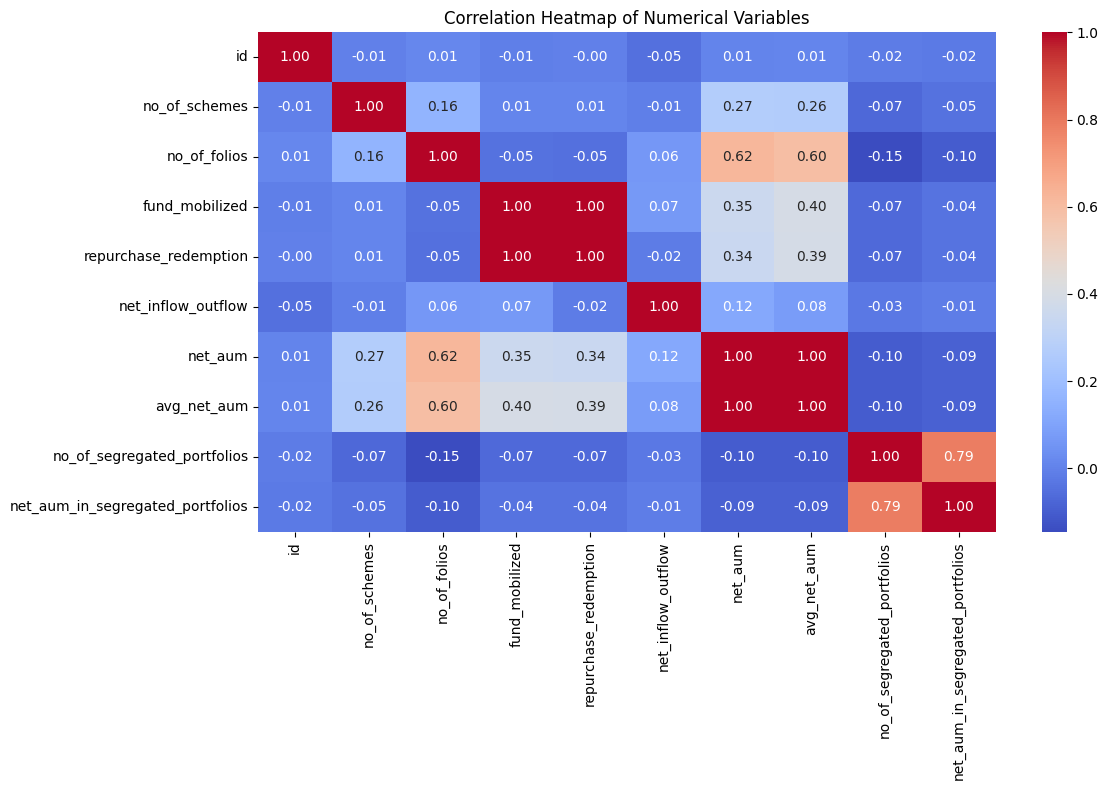

In [87]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

The correlation heatmap shows the relationships among the key numerical variables in the mutual fund dataset. Financial variables such as fund mobilization, repurchase/redemption, net inflow/outflow, and Net AUM can be compared to identify positive and negative associations. The analysis helps identify variables that move together and provides a basis for understanding relationships among fund flows, investor activity, and asset size. However, correlation indicates association rather than causation.

####**Distribution Analysis**

let's analyze the distributions of important numerical variables. This helps to identify skewness, extreme values, and potential outliers in the dataset.

**Create histograms for net_aum and no_of_folios**

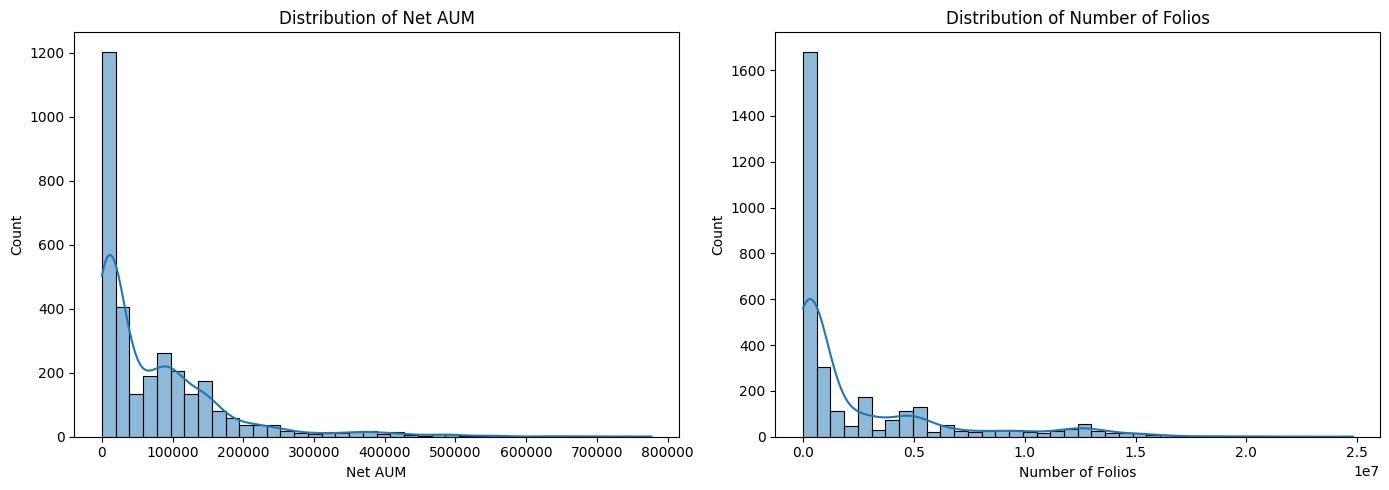

In [88]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x="net_aum", bins=40, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Net AUM")
axes[0].set_xlabel("Net AUM")

sns.histplot(data=df, x="no_of_folios", bins=40, kde=True, ax=axes[1])
axes[1].set_title("Distribution of Number of Folios")
axes[1].set_xlabel("Number of Folios")

plt.tight_layout()
plt.show()


The histograms of Net AUM and Number of Folios reveal strongly right-skewed distributions with long right tails. Most observations are concentrated at relatively low values, while a smaller number of observations exhibit substantially higher values. These extreme values may reflect differences in the size and investor participation of mutual fund schemes. The distributions suggest that the median may be a more representative measure of central tendency than the mean. Further investigation of extreme observations using descriptive statistics and boxplots is recommended before deciding whether any outlier treatment is necessary.

####**Create boxplots to investigate outliers**

Since histograms showed strong right-skewness, boxplots will help us examine the spread of the data and identify potential outliers.

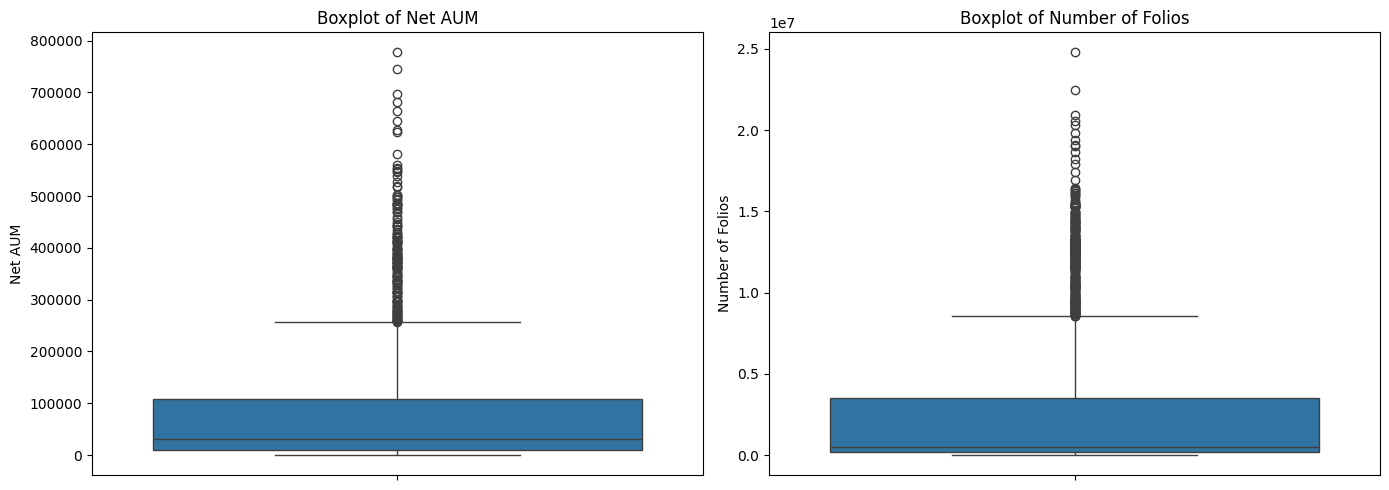

In [89]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(y=df["net_aum"], ax=axes[0])
axes[0].set_title("Boxplot of Net AUM")
axes[0].set_ylabel("Net AUM")

sns.boxplot(y=df["no_of_folios"], ax=axes[1])
axes[1].set_title("Boxplot of Number of Folios")
axes[1].set_ylabel("Number of Folios")

plt.tight_layout()
plt.show()


Both Net AUM and Number of Folios contain many potential outliers and are strongly right-skewed.&#x20;

## 1. Boxplot of Net AUM

- Median: The line inside the box represents the median Net AUM. It lies relatively low compared with the overall range.
- Spread: The box represents the interquartile range (IQR), containing the middle 50% of observations.
- Upper whisker: The whisker extends to approximately 250,000–260,000.
- Potential outliers: Many points lie above the upper whisker, with some reaching approximately 780,000.

Insight: Most observations have comparatively low Net AUM, but a smaller number have substantially higher values. These may represent larger mutual fund schemes or periods with unusually high assets.

## 2. Boxplot of Number of Folios

- Median: The median is relatively close to the lower end of the distribution.
- Spread: The box shows the middle 50% of folio counts, with considerable variation across observations.
- Upper whisker: The whisker extends to approximately 8.5 million folios.
- Potential outliers: Numerous observations exceed the upper whisker, and the highest values approach 25 million.


Insight: Most observations have relatively low folio counts compared with a small number of observations with very large investor bases.

## In short

There are numerous points beyond the whiskers, which means many observations meet the statistical definition of potential outliers. There are longer upper tails, means both variables are positively skewed. Median is near the lower end which denotes that the distribution is concentrated toward smaller values. Also we can see very large maximum values, that means a few observations may strongly influence the mean and standard deviation.

Important: A boxplot typically classifies observations beyond 1.5 times IQR from a quartile as potential outliers. It does not prove that those observations are errors. In mutual fund data, large AUM and folio counts can be completely legitimate.

####**Analyze the distributions using a log scale**

Because both variables are strongly right-skewed, a log transformation for visualization can make smaller and larger observations easier to compare. We'll use log1p, which safely handles zero values.

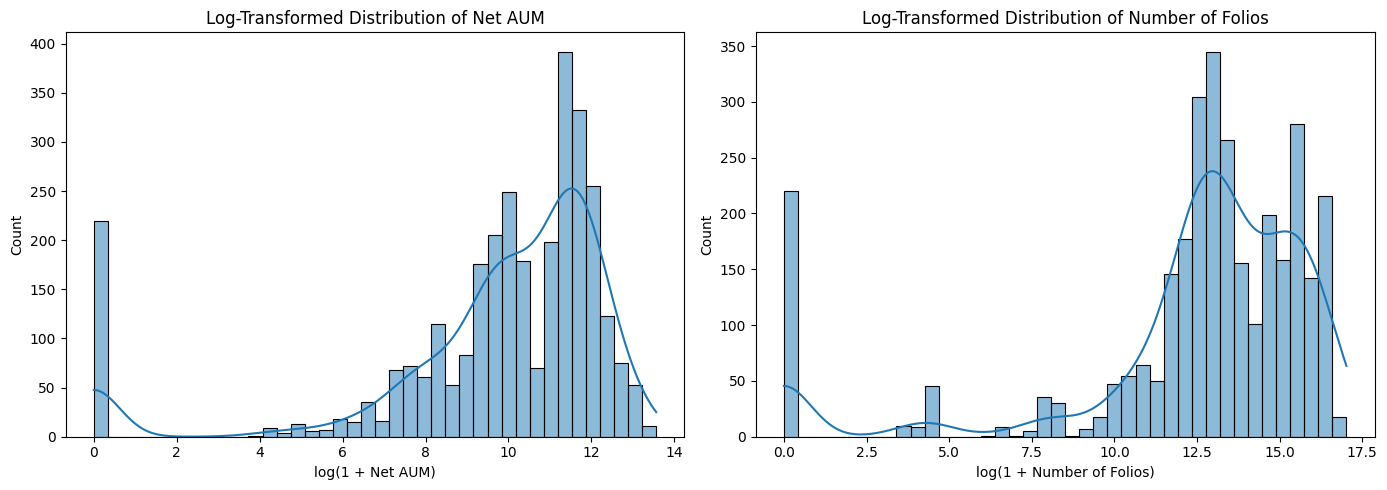

In [90]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    x=np.log1p(df["net_aum"].dropna()),
    bins=40,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Log-Transformed Distribution of Net AUM")
axes[0].set_xlabel("log(1 + Net AUM)")

sns.histplot(
    x=np.log1p(df["no_of_folios"].dropna()),
    bins=40,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Log-Transformed Distribution of Number of Folios")
axes[1].set_xlabel("log(1 + Number of Folios)")

plt.tight_layout()
plt.show()


The log-transformed distributions of Net AUM and Number of Folios help reduce the visual impact of extreme values and make the spread of observations easier to examine. This transformation improves the visualization of highly skewed financial data by compressing large values. The plots can help reveal patterns among smaller observations that were less visible in the original distributions. However, the transformation does not remove outliers or change the original dataset.

####**Calculating the IQR-based outlier counts**

In [91]:
# Calculate IQR-based outlier counts
for col in ["net_aum", "no_of_folios"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\nColumn: {col}")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)
    print("Number of potential outliers:", len(outliers))
    print("Percentage of potential outliers:",
          round(len(outliers) / df[col].notna().sum() * 100, 2), "%")


Column: net_aum
Q1: 9137.099999999999
Q3: 108359.70499999999
IQR: 99222.60499999998
Lower bound: -139696.80749999997
Upper bound: 257193.61249999996
Number of potential outliers: 161
Percentage of potential outliers: 5.17 %

Column: no_of_folios
Q1: 172277.5
Q3: 3522135.0
IQR: 3349857.5
Lower bound: -4852508.75
Upper bound: 8546921.25
Number of potential outliers: 318
Percentage of potential outliers: 10.21 %


The IQR-based outlier analysis identified 161 potential outliers in Net AUM, representing 5.17% of observations, and 318 potential outliers in the Number of Folios, representing 10.21%. Both variables exhibit upper-tail outliers, consistent with their positively skewed distributions. The higher proportion of potential outliers in the Number of Folios indicates that unusually large folio counts are relatively more prevalent in the dataset. These observations will be retained unless further investigation identifies data-quality issues, as they may represent genuine differences in mutual fund size and investor participation.

####**Grouped analysis of Net AUM by scheme category and scheme type**

In [92]:
#compare mutual fund categories and scheme structures using a meaningful financial metric.


# Average Net AUM by Scheme Category
category_aum = df.groupby("scheme_category")["net_aum"].mean().sort_values(
    ascending=False
)

print(category_aum)

# Average Net AUM by Scheme Type
type_aum = df.groupby("scheme_type")["net_aum"].mean().sort_values(
    ascending=False
)

print(type_aum)


scheme_category
Growth/Equity Oriented Schemes    98142.474743
Other Schemes                     81729.085625
Hybrid Schemes                    76235.281510
Income/Debt Oriented Schemes      65309.107768
Solution Oriented Schemes         14260.616094
Name: net_aum, dtype: float64
scheme_type
Open ended Schemes     93062.527216
Close Ended Schemes    12861.613460
Interval Schemes         218.877031
Name: net_aum, dtype: float64


**Key findings**

Average Net AUM by scheme category
- Growth/Equity Oriented Schemes have the highest average Net AUM at approximately 98,142.
- Other Schemes follow at 81,729, then Hybrid Schemes at 76,235.
- Solution Oriented Schemes have the lowest average at approximately 14,261.
Average Net AUM by scheme type
- Open-ended Schemes lead with an average Net AUM of approximately 93,063.
- Close-ended Schemes average 12,862.
- Interval Schemes have the lowest average at approximately 219.
These results suggest that average Net AUM varies substantially across both scheme categories and scheme types. Because your distributions are strongly right-skewed, these means may be influenced by unusually large observations.

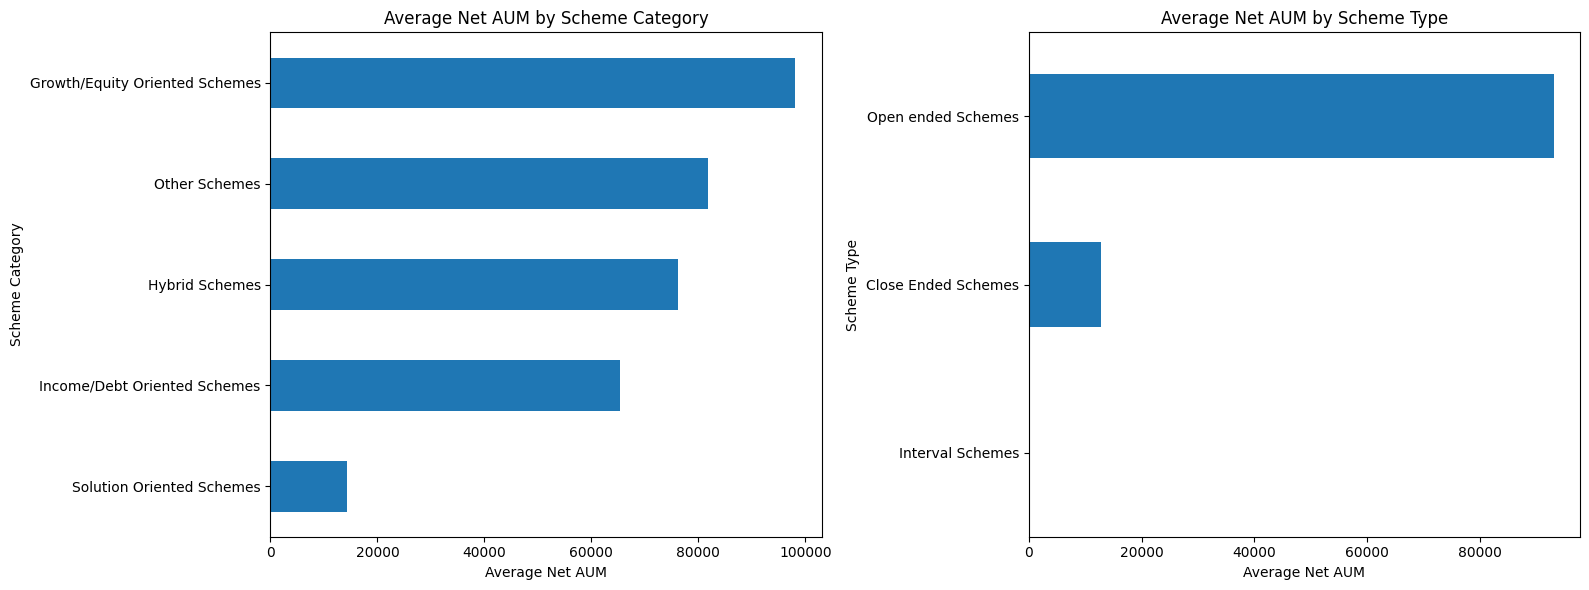

In [93]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Average Net AUM by Scheme Category
category_aum.sort_values().plot(
    kind="barh",
    ax=axes[0]
)
axes[0].set_title("Average Net AUM by Scheme Category")
axes[0].set_xlabel("Average Net AUM")
axes[0].set_ylabel("Scheme Category")

# Average Net AUM by Scheme Type
type_aum.sort_values().plot(
    kind="barh",
    ax=axes[1]
)
axes[1].set_title("Average Net AUM by Scheme Type")
axes[1].set_xlabel("Average Net AUM")
axes[1].set_ylabel("Scheme Type")

plt.tight_layout()
plt.show()


####**Median Net AUM Analysis by Scheme Category and Scheme Type**

In [94]:
print("Median Net AUM by Scheme Category:")
print(
    df.groupby("scheme_category")["net_aum"]
    .median()
    .sort_values(ascending=False)
)

print("\nMedian Net AUM by Scheme Type:")
print(
    df.groupby("scheme_type")["net_aum"]
    .median()
    .sort_values(ascending=False)
)


Median Net AUM by Scheme Category:
scheme_category
Growth/Equity Oriented Schemes    83302.850
Hybrid Schemes                    62499.995
Income/Debt Oriented Schemes      28968.355
Other Schemes                     14045.495
Solution Oriented Schemes         13627.730
Name: net_aum, dtype: float64

Median Net AUM by Scheme Type:
scheme_type
Open ended Schemes     69182.81
Close Ended Schemes     2564.75
Interval Schemes           0.00
Name: net_aum, dtype: float64


The median analysis reveals substantial differences in typical Net AUM across mutual fund categories and scheme types. Growth/Equity Oriented Schemes recorded the highest median Net AUM among categories, while Open-ended Schemes recorded the highest median among scheme types. Interval Schemes had a median Net AUM of zero, warranting further investigation. Compared with the mean values, the medians provide a less outlier-sensitive measure of central tendency. The differences between the means and medians are consistent with the right-skewed distributions observed earlier.

**Summary Table**

In [95]:
eda_summary = df.groupby("scheme_category").agg(
    sum_of_reported_schemes=("no_of_schemes", "sum"),
    total_folios=("no_of_folios", "sum"),
    total_fund_mobilized=("fund_mobilized", "sum"),
    total_redemption=("repurchase_redemption", "sum"),
    total_net_inflow_outflow=("net_inflow_outflow", "sum"),
    total_net_aum=("net_aum", "sum")
).sort_values("total_net_aum", ascending=False)

eda_summary

,sum_of_reported_schemes,total_folios,total_fund_mobilized,total_redemption,total_net_inflow_outflow,total_net_aum
scheme_category,,,,,,
Income/Debt Oriented Schemes,46929,482014710,58723619.24,58711910.75,11708.75,87775440.84
Growth/Equity Oriented Schemes,27304,5399301356,2024982.13,1371579.10,653402.97,85874665.40
Other Schemes,17186,902069434,1111431.71,571340.57,540091.23,31383968.88
Hybrid Schemes,8845,704516880,1239037.36,980234.27,258803.03,29274348.10
Solution Oriented Schemes,2219,356938544,21999.43,11460.71,10538.84,1825358.86


**EDA Summary and Key Insights**

The exploratory analysis reveals substantial differences in mutual fund scheme characteristics and financial activity. Open-ended schemes dominate the dataset, accounting for 2,475 of the 3,115 records, while close-ended and interval schemes have considerably fewer observations.

Growth/Equity Oriented Schemes recorded the highest average and median Net AUM among the scheme categories, while Open-ended Schemes had the highest average and median Net AUM among scheme types. The difference between mean and median values indicates that extreme observations influence the average Net AUM.

The distributions of Net AUM and Number of Folios are strongly right-skewed, with numerous potential outliers. These extreme values were retained because they may represent genuine differences in fund size and investor participation rather than data-entry errors.

The correlation analysis provides an overview of relationships among the key numerical financial variables, helping identify variables that move together. The analysis supports further investigation of financial flows, assets, and investor activity.

Overall, the EDA indicates that the mutual fund dataset contains substantial variation in scheme size, investor participation, and financial activity, providing a strong foundation for the subsequent time-series and financial analysis.

**Time-Series Analysis**

**Correct and verify the dates**

In [96]:
# Step 1: Correct the date format
df["date"] = pd.to_datetime(
    df["date"].astype(str),
    format="%Y-%d-%m",
    errors="raise"
)

# Verify the dates
print("Date column data type:", df["date"].dtype)
print("Earliest date:", df["date"].min())
print("Latest date:", df["date"].max())
print("Number of unique reporting dates:", df["date"].nunique())


Date column data type: datetime64[ns]
Earliest date: 2019-04-01 00:00:00
Latest date: 2024-07-01 00:00:00
Number of unique reporting dates: 64


**Prepare the monthly time-series data**

In [97]:
# Step 2: Prepare monthly data

ts_df = df.copy()

# Sort the data by date
ts_df = ts_df.sort_values("date")

# Group all schemes belonging to the same reporting date
monthly = ts_df.groupby("date")[
    [
        "net_aum",
        "no_of_folios",
        "fund_mobilized",
        "repurchase_redemption",
        "net_inflow_outflow"
    ]
].sum()

# Display the results
print("Shape of monthly dataset:", monthly.shape)

print("\nFirst 3 reporting dates:")
print(monthly.head(3))

print("\nLast 3 reporting dates:")
print(monthly.tail(3))


Shape of monthly dataset: (64, 5)

First 3 reporting dates:
               net_aum  no_of_folios  fund_mobilized  repurchase_redemption  \
date                                                                          
2019-04-01  2478756.91      82736339      1873516.14             1773056.41   
2019-05-01  2593559.62      83242056      2287290.51             2210300.70   
2019-06-01  2425040.39      83771689      1867479.83             2027294.26   

            net_inflow_outflow  
date                            
2019-04-01           100459.73  
2019-05-01            76989.81  
2019-06-01          -159814.38  

Last 3 reporting dates:
               net_aum  no_of_folios  fund_mobilized  repurchase_redemption  \
date                                                                          
2024-05-01  5891160.47     185968222       988540.62              878023.67   
2024-06-01  6115581.91     191047118      1058804.41             1102440.96   
2024-07-01  6496653.14     198406294  

**Plot the monthly Net AUM trend**

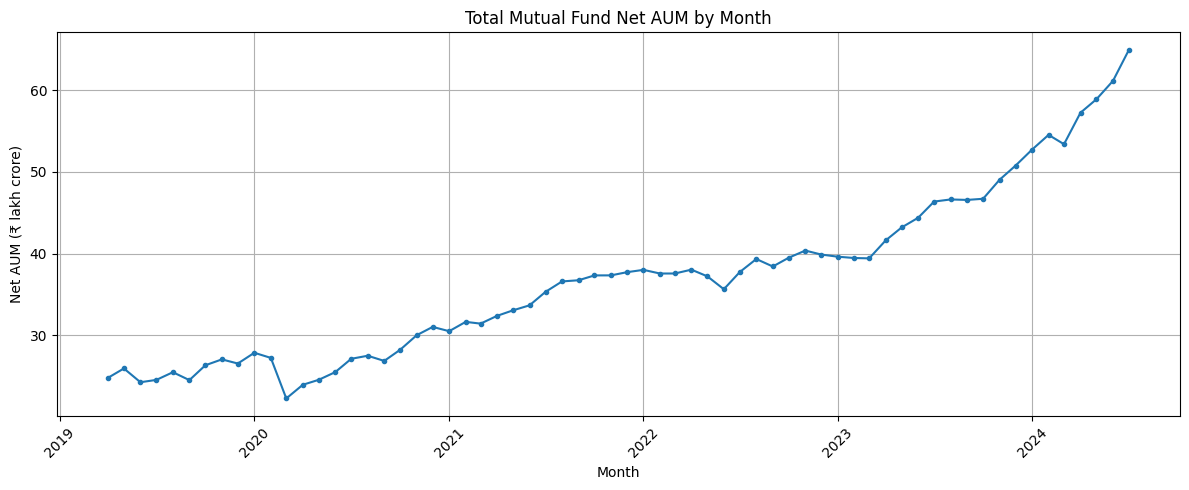

In [98]:
# Step 3: Monthly Net AUM trend

aum_lakh_cr = monthly["net_aum"] / 100000

plt.figure(figsize=(12, 5))

plt.plot(
    monthly.index,
    aum_lakh_cr,
    marker="o",
    markersize=3
)

plt.title("Total Mutual Fund Net AUM by Month")
plt.xlabel("Month")
plt.ylabel("Net AUM (₹ lakh crore)")
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Net AUM shows a clear overall upward trend from April 2019 to July 2024, increasing from 2,478,756.91 to 6,496,653.14. However, the trend is not completely smooth, with several temporary declines, particularly around March 2020. The strong recovery after periods of decline indicates substantial long-term growth in assets managed by the industry.

**Yearly Net AUM trend**

Yearly Net AUM:
date
2019    22940962.49
2020    32205621.14
2021    41372321.67
2022    45931622.70
2023    53385551.07
2024    40297703.01
Name: net_aum, dtype: float64


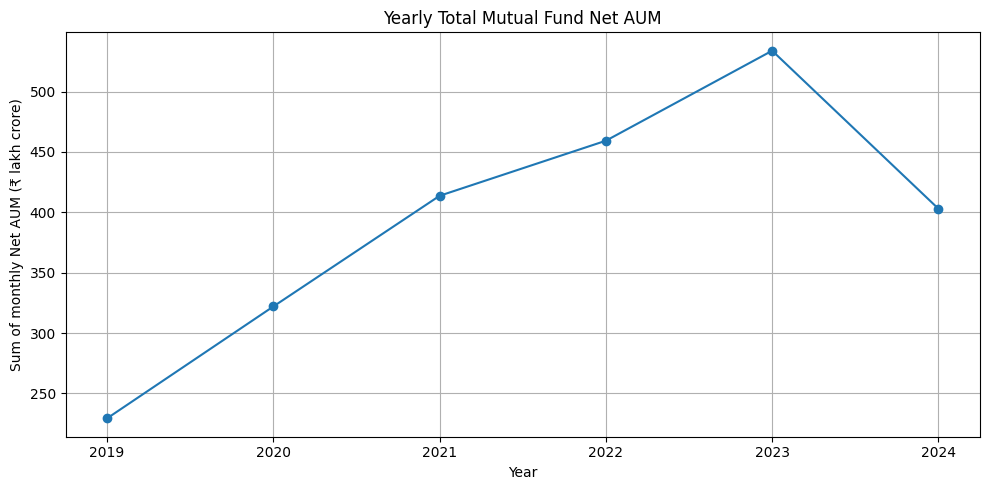

In [99]:
# Step 4: Yearly Net AUM trend

yearly_aum = monthly["net_aum"].groupby(monthly.index.year).sum()

print("Yearly Net AUM:")
print(yearly_aum)

plt.figure(figsize=(10, 5))
plt.plot(yearly_aum.index, yearly_aum / 100000, marker="o")
plt.title("Yearly Total Mutual Fund Net AUM")
plt.xlabel("Year")
plt.ylabel("Sum of monthly Net AUM (₹ lakh crore)")
plt.grid(True)
plt.xticks(yearly_aum.index)
plt.tight_layout()
plt.show()

The sum of monthly AUM increased consistently from 2019 through 2023. The 2024 value is lower because the year contains only January to July observations, so it should not be interpreted as a decline in annual AUM.

**Yearly Net Inflow/Outflow Trend**

In this step, we'll aggregate monthly net inflow/outflow figures by year and create a chart to understand how investor money flows into and out of mutual fund schemes over time.


Net inflow/outflow is calculated as fund mobilized minus repurchase/redemption. Positive values indicate net inflows, while negative values indicate net outflows.

**Calculate yearly net inflow/outflow**

In [100]:
# Step 5.1: Calculate yearly net inflow/outflow

yearly_net_flow = monthly["net_inflow_outflow"].groupby(
    monthly.index.year
).sum()

# Display the yearly summary
print("YEARLY NET INFLOW/OUTFLOW")
print("-" * 50)
print(yearly_net_flow.to_string())

print("\nTotal years:", len(yearly_net_flow))


YEARLY NET INFLOW/OUTFLOW
--------------------------------------------------
date
2019    181562.38
2020    181411.09
2021    188585.63
2022     71443.30
2023    274216.57
2024    577325.85

Total years: 6


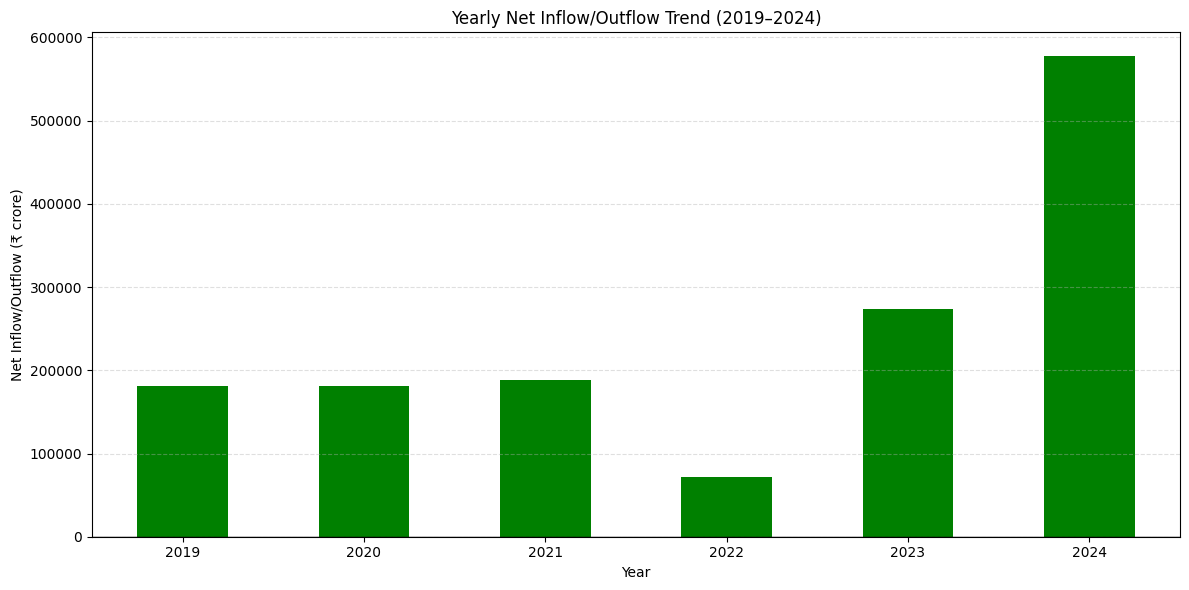

In [101]:
plt.figure(figsize=(12, 6))

yearly_net_flow.plot(
    kind="bar",
    color=[
        "green" if value >= 0 else "red"
        for value in yearly_net_flow
    ]
)

plt.axhline(y=0, color="black", linewidth=1)

plt.title("Yearly Net Inflow/Outflow Trend (2019–2024)")
plt.xlabel("Year")
plt.ylabel("Net Inflow/Outflow (₹ crore)")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


Net flows remained relatively stable from 2019 to 2021, declined substantially in 2022, and then increased sharply in 2023 and 2024. 2022 recorded the weakest annual net flow, while 2024 recorded the strongest total among the available years. However, 2024 covers only January to July and should therefore not be compared directly with complete years.

**Identify the strongest and weakest years**

In [102]:
print("STRONGEST YEAR (Highest Net Flow)")
print("-" * 50)
print("Year:", yearly_net_flow.idxmax())
print("Net flow:", round(yearly_net_flow.max(), 2))

print("\nWEAKEST YEAR (Lowest Net Flow)")
print("-" * 50)
print("Year:", yearly_net_flow.idxmin())
print("Net flow:", round(yearly_net_flow.min(), 2))

STRONGEST YEAR (Highest Net Flow)
--------------------------------------------------
Year: 2024
Net flow: 577325.85

WEAKEST YEAR (Lowest Net Flow)
--------------------------------------------------
Year: 2022
Net flow: 71443.3


The year 2024 had the highest cumulative net inflow, while 2022 had the lowest. This indicates a substantial difference in net flows across the analyzed periods.

**Calculate year-over-year changes**

In [103]:
# Calculate year-over-year changes

yearly_flow_change = yearly_net_flow.diff()

yearly_flow_summary = pd.DataFrame({
    "Yearly_Net_Flow": yearly_net_flow,
    "Change_From_Previous_Year": yearly_flow_change
})

print("YEARLY NET FLOW COMPARISON")
print("-" * 60)
print(yearly_flow_summary.round(2).to_string())

YEARLY NET FLOW COMPARISON
------------------------------------------------------------
      Yearly_Net_Flow  Change_From_Previous_Year
date                                            
2019        181562.38                        NaN
2020        181411.09                    -151.29
2021        188585.63                    7174.54
2022         71443.30                 -117142.33
2023        274216.57                  202773.27
2024        577325.85                  303109.28


**Monthly Net Inflow/Outflow Trend**

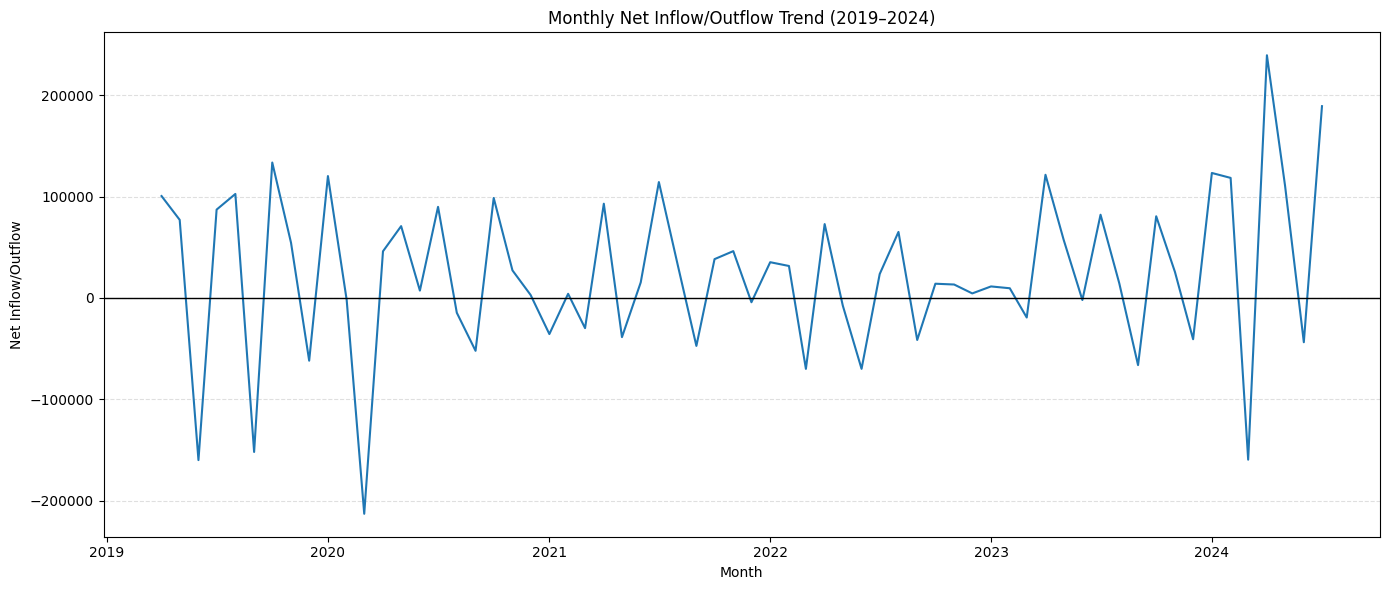

In [104]:
# Plot monthly net inflow/outflow trend

plt.figure(figsize=(14, 6))

plt.plot(
    monthly.index,
    monthly["net_inflow_outflow"],
    linewidth=1.5
)

plt.axhline(y=0, color="black", linewidth=1)

plt.title("Monthly Net Inflow/Outflow Trend (2019–2024)")
plt.xlabel("Month")
plt.ylabel("Net Inflow/Outflow")

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Monthly net flows were highly volatile, with both substantial inflows and outflows. April 2024 recorded the highest positive monthly flow, while March 2020 recorded the largest negative flow. Despite these fluctuations, positive-flow months were more frequent, accounting for 65.62% of observations.

**Identify the highest and lowest monthly net flows**

In [105]:
# Highest and Lowest Monthly Net Inflow/Outflow

highest_month = monthly["net_inflow_outflow"].idxmax()
lowest_month = monthly["net_inflow_outflow"].idxmin()

print("HIGHEST MONTHLY NET FLOW")
print("-" * 50)
print("Month:", highest_month.strftime("%B %Y"))
print("Net flow:", round(monthly.loc[highest_month, "net_inflow_outflow"], 2))

print("\nLOWEST MONTHLY NET FLOW")
print("-" * 50)
print("Month:", lowest_month.strftime("%B %Y"))
print("Net flow:", round(monthly.loc[lowest_month, "net_inflow_outflow"], 2))

HIGHEST MONTHLY NET FLOW
--------------------------------------------------
Month: April 2024
Net flow: 239232.85

LOWEST MONTHLY NET FLOW
--------------------------------------------------
Month: March 2020
Net flow: -212737.09


**Calculate Monthly Net Flow Statistics**

In [106]:
# Monthly Net Flow Statistics

monthly_flow_stats = monthly["net_inflow_outflow"].describe()

print("MONTHLY NET INFLOW/OUTFLOW STATISTICS")
print("-" * 50)
print(monthly_flow_stats.to_string())

MONTHLY NET INFLOW/OUTFLOW STATISTICS
--------------------------------------------------
count        64.000000
mean      23039.762812
std       81540.082680
min     -212737.090000
25%      -21884.565000
50%       19462.600000
75%       80907.900000
max      239232.850000


 **Correlation Analysis**


We'll examine the relationships between these three variables in your monthly dataset:
- total_net_aum
- total_folios
- net_inflow_outflow

**Calculate the correlation matrix**

In [107]:
correlation_data = monthly[
    [
        "net_aum",
        "no_of_folios",
        "net_inflow_outflow"
    ]
]

correlation_matrix = correlation_data.corr()

print("CORRELATION MATRIX")
print("-" * 50)
print(correlation_matrix.round(3))

CORRELATION MATRIX
--------------------------------------------------
                    net_aum  no_of_folios  net_inflow_outflow
net_aum               1.000         0.973               0.237
no_of_folios          0.973         1.000               0.167
net_inflow_outflow    0.237         0.167               1.000


**Correlation Heatmap**

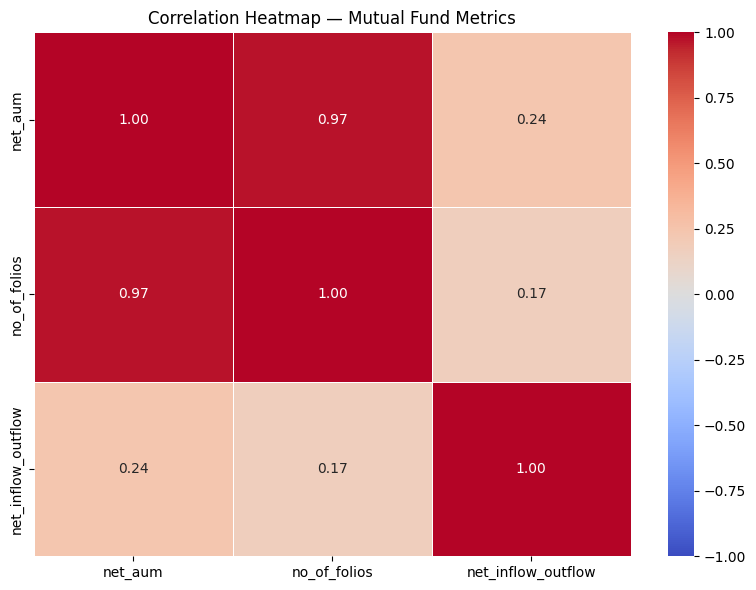

In [108]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Correlation Heatmap — Mutual Fund Metrics")
plt.tight_layout()
plt.show()

**Analyze relationships between fund mobilization and redemptions**

We'll now examine the relationship between fund mobilization, repurchase/redemption, and net inflow/outflow using the existing monthly DataFrame.

**Calculate the correlation matrix**

In [109]:
# Fund Mobilization and Redemption Correlation

flow_data = monthly[
    [
        "fund_mobilized",
        "repurchase_redemption",
        "net_inflow_outflow"
    ]
]

flow_correlation = flow_data.corr()

print("FUND MOBILIZATION & REDEMPTION CORRELATION")
print("-" * 55)
print(flow_correlation.round(3))

FUND MOBILIZATION & REDEMPTION CORRELATION
-------------------------------------------------------
                       fund_mobilized  repurchase_redemption  \
fund_mobilized                  1.000                  0.977   
repurchase_redemption           0.977                  1.000   
net_inflow_outflow              0.029                 -0.185   

                       net_inflow_outflow  
fund_mobilized                      0.029  
repurchase_redemption              -0.185  
net_inflow_outflow                  1.000  


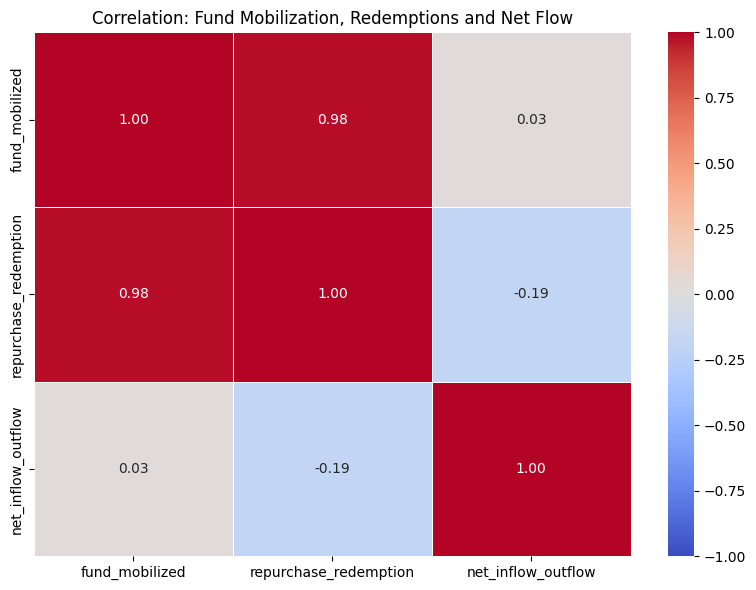

In [110]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    flow_correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Correlation: Fund Mobilization, Redemptions and Net Flow")
plt.tight_layout()
plt.show()

**Monthly AUM Growth Analysis**

We'll examine how the total assets under management (net_aum) change from month to month.

**Calculate monthly AUM change and percentage change**

In [111]:
# Monthly AUM Growth Analysis

monthly["aum_change"] = monthly["net_aum"].diff()

monthly["aum_pct_change"] = (
    monthly["net_aum"].pct_change() * 100
)

print("MONTHLY AUM GROWTH")
print("-" * 50)

print(
    monthly[
        ["net_aum", "aum_change", "aum_pct_change"]
    ].head(10).round(2).to_string()
)

MONTHLY AUM GROWTH
--------------------------------------------------
               net_aum  aum_change  aum_pct_change
date                                              
2019-04-01  2478756.91         NaN             NaN
2019-05-01  2593559.62   114802.71            4.63
2019-06-01  2425040.39  -168519.23           -6.50
2019-07-01  2453626.37    28585.98            1.18
2019-08-01  2547593.77    93967.40            3.83
2019-09-01  2450786.75   -96807.02           -3.80
2019-10-01  2632824.45   182037.70            7.43
2019-11-01  2704699.42    71874.97            2.73
2019-12-01  2654074.81   -50624.61           -1.87
2020-01-01  2785803.65   131728.84            4.96


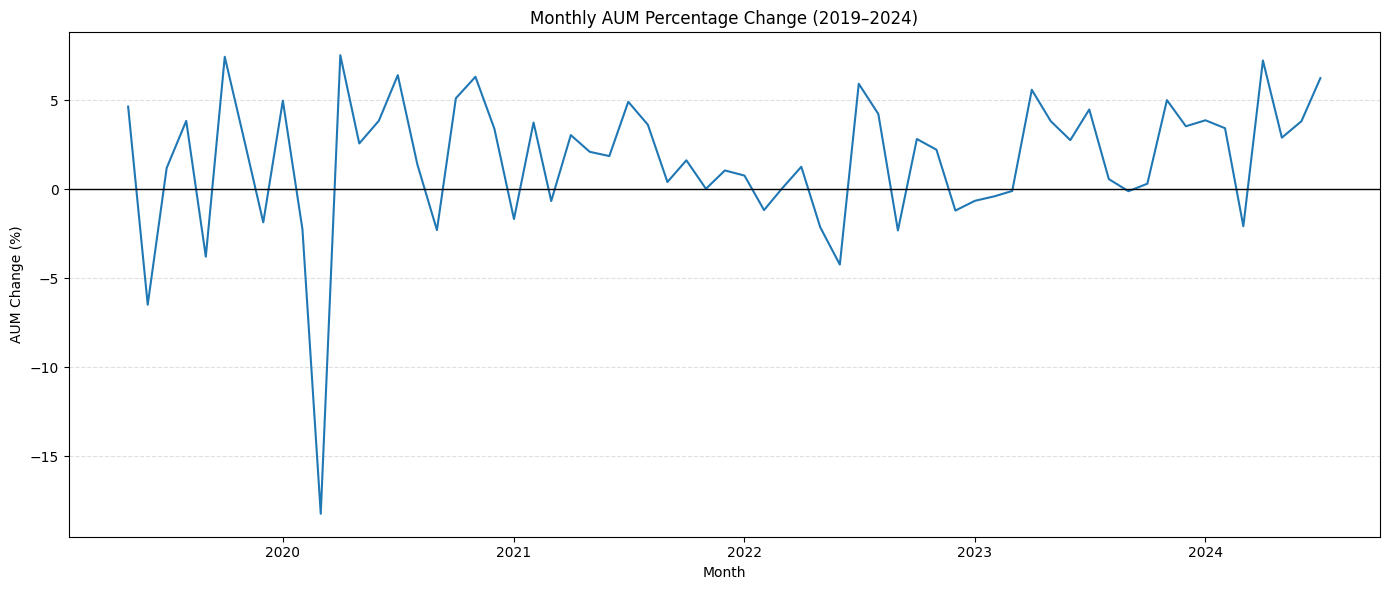

In [112]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly.index,
    monthly["aum_pct_change"],
    linewidth=1.5
)

plt.axhline(y=0, color="black", linewidth=1)

plt.title("Monthly AUM Percentage Change (2019–2024)")
plt.xlabel("Month")
plt.ylabel("AUM Change (%)")

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Monthly AUM growth fluctuated considerably throughout the study period. The sharpest decline occurred in March 2020 at −18.24%, followed by a strong recovery in April 2020 with 7.51% growth. This demonstrates that aggregate AUM can experience substantial short-term movements even when the long-term trend remains positive.

**Identify the Highest and Lowest Monthly AUM Growth**

In [113]:
# Highest and Lowest Monthly AUM Growth

aum_pct_change = monthly["aum_pct_change"].dropna()

highest_growth_month = aum_pct_change.idxmax()
lowest_growth_month = aum_pct_change.idxmin()

print("HIGHEST MONTHLY AUM GROWTH")
print("-" * 50)
print("Month:", highest_growth_month.strftime("%B %Y"))
print("Growth (%):", round(aum_pct_change.max(), 2))

print("\nLOWEST MONTHLY AUM GROWTH")
print("-" * 50)
print("Month:", lowest_growth_month.strftime("%B %Y"))
print("Growth (%):", round(aum_pct_change.min(), 2))

HIGHEST MONTHLY AUM GROWTH
--------------------------------------------------
Month: April 2020
Growth (%): 7.51

LOWEST MONTHLY AUM GROWTH
--------------------------------------------------
Month: March 2020
Growth (%): -18.24


**Monthly Folio Growth Analysis**

We'll examine changes in the number of investor folios over time using your existing monthly DataFrame.

**Calculate monthly folio change and percentage change**

In [114]:
# Monthly Folio Growth Analysis

monthly["folios_change"] = monthly["no_of_folios"].diff()

monthly["folios_pct_change"] = (
    monthly["no_of_folios"].pct_change() * 100
)

print("MONTHLY FOLIO GROWTH")
print("-" * 50)

print(
    monthly[
        ["no_of_folios", "folios_change", "folios_pct_change"]
    ].head(10).round(2).to_string()
)

MONTHLY FOLIO GROWTH
--------------------------------------------------
            no_of_folios  folios_change  folios_pct_change
date                                                      
2019-04-01      82736339            NaN                NaN
2019-05-01      83242056       505717.0               0.61
2019-06-01      83771689       529633.0               0.64
2019-07-01      84800409      1028720.0               1.23
2019-08-01      85281222       480813.0               0.57
2019-09-01      85626244       345022.0               0.40
2019-10-01      86256880       630636.0               0.74
2019-11-01      86518585       261705.0               0.30
2019-12-01      87126725       608140.0               0.70
2020-01-01      88533153      1406428.0               1.61


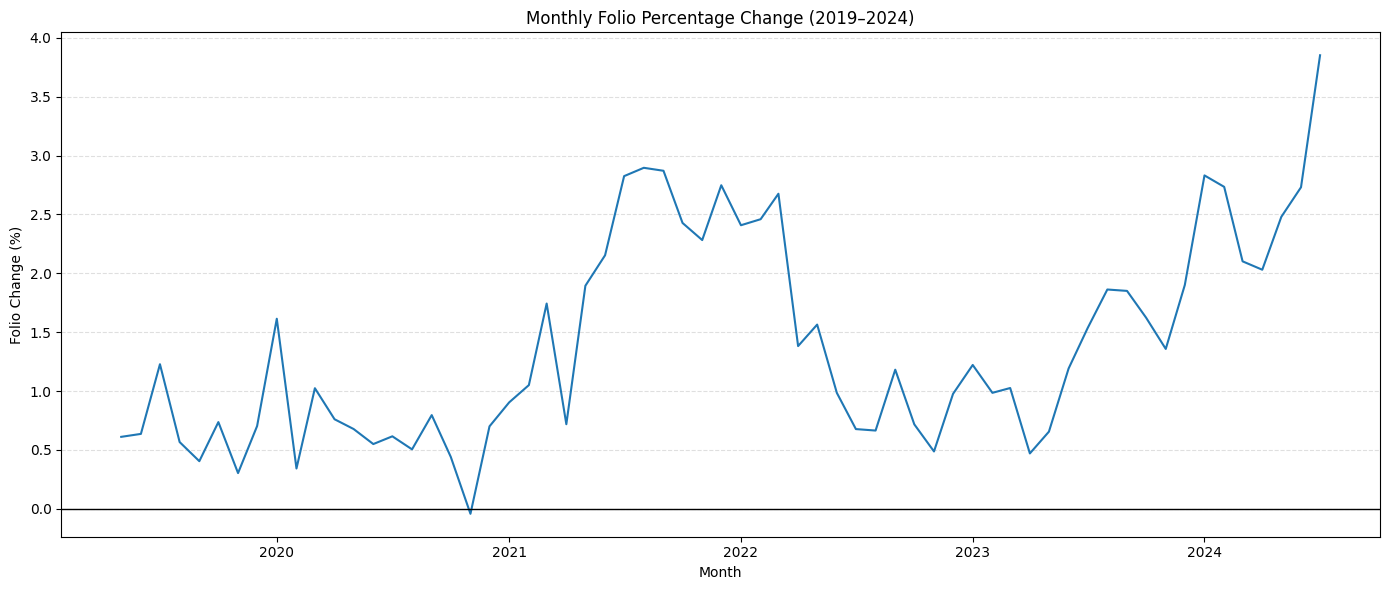

In [115]:
# Monthly Folio Percentage Growth Trend

plt.figure(figsize=(14, 6))

plt.plot(
    monthly.index,
    monthly["folios_pct_change"],
    linewidth=1.5
)

plt.axhline(y=0, color="black", linewidth=1)

plt.title("Monthly Folio Percentage Change (2019–2024)")
plt.xlabel("Month")
plt.ylabel("Folio Change (%)")

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Folio growth was generally more stable than AUM growth. Most months recorded positive changes, with the strongest growth occurring in July 2024 at 3.852%. The smallest change occurred in November 2020, when folios declined slightly by 0.0423%.

**Identify the Highest and Lowest Monthly Folio Growth**

In [116]:
# Highest and Lowest Monthly Folio Growth

folios_pct_change = monthly["folios_pct_change"].dropna()

highest_growth_month = folios_pct_change.idxmax()
lowest_growth_month = folios_pct_change.idxmin()

print("HIGHEST MONTHLY FOLIO GROWTH")
print("-" * 50)
print("Month:", highest_growth_month.strftime("%B %Y"))
print("Growth (%):", round(folios_pct_change.max(), 4))

print("\nLOWEST MONTHLY FOLIO GROWTH")
print("-" * 50)
print("Month:", lowest_growth_month.strftime("%B %Y"))
print("Growth (%):", round(folios_pct_change.min(), 4))

HIGHEST MONTHLY FOLIO GROWTH
--------------------------------------------------
Month: July 2024
Growth (%): 3.852

LOWEST MONTHLY FOLIO GROWTH
--------------------------------------------------
Month: November 2020
Growth (%): -0.0423


**AUM Growth vs. Net Inflow/Outflow**

In this step, we'll compare monthly changes in assets under management (AUM) with monthly net inflow/outflow.

**Calculate the relationship between AUM change and net flow**

In [117]:
# AUM Change vs. Net Inflow/Outflow

monthly["aum_change_minus_net_flow"] = (
    monthly["aum_change"] - monthly["net_inflow_outflow"]
)

print("AUM CHANGE VS NET INFLOW/OUTFLOW")
print("-" * 55)

print(
    monthly[
        [
            "aum_change",
            "net_inflow_outflow",
            "aum_change_minus_net_flow"
        ]
    ].head(10).round(2).to_string()
)

AUM CHANGE VS NET INFLOW/OUTFLOW
-------------------------------------------------------
            aum_change  net_inflow_outflow  aum_change_minus_net_flow
date                                                                 
2019-04-01         NaN           100459.73                        NaN
2019-05-01   114802.71            76989.81                   37812.90
2019-06-01  -168519.23          -159814.38                   -8704.85
2019-07-01    28585.98            87087.70                  -58501.72
2019-08-01    93967.40           102538.26                   -8570.86
2019-09-01   -96807.02          -151790.14                   54983.12
2019-10-01   182037.70           133481.92                   48555.78
2019-11-01    71874.97            54419.18                   17455.79
2019-12-01   -50624.61           -61809.70                   11185.09
2020-01-01   131728.84           120148.51                   11580.33


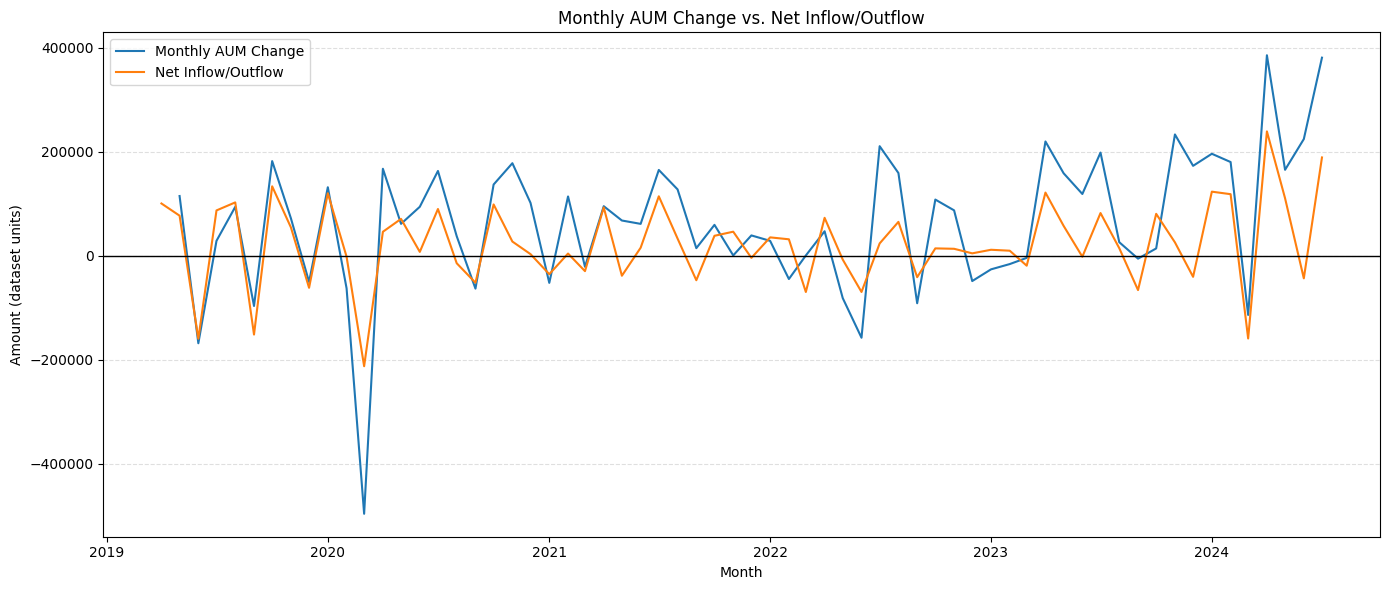

In [118]:
# Compare Monthly AUM Change and Net Flow

plt.figure(figsize=(14, 6))

plt.plot(
    monthly.index,
    monthly["aum_change"],
    label="Monthly AUM Change",
    linewidth=1.5
)

plt.plot(
    monthly.index,
    monthly["net_inflow_outflow"],
    label="Net Inflow/Outflow",
    linewidth=1.5
)

plt.axhline(y=0, color="black", linewidth=1)

plt.title("Monthly AUM Change vs. Net Inflow/Outflow")
plt.xlabel("Month")
plt.ylabel("Amount (dataset units)")
plt.legend()

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Monthly AUM changes and net inflow/outflow generally moved in the same direction, with a strong positive correlation of 0.784. This indicates that months with higher net inflows tended to experience larger increases in AUM, although the two measures did not move identically in every month.

**Correlation Between AUM Change and Net Flow**

Now we'll calculate the correlation between monthly AUM change and monthly net inflow/outflow.

In [119]:
# Correlation Between AUM Change and Net Flow

aum_flow_correlation = monthly[
    ["aum_change", "net_inflow_outflow"]
].corr()

print("AUM CHANGE VS NET INFLOW/OUTFLOW CORRELATION")
print("-" * 55)
print(aum_flow_correlation.round(3))

AUM CHANGE VS NET INFLOW/OUTFLOW CORRELATION
-------------------------------------------------------
                    aum_change  net_inflow_outflow
aum_change               1.000               0.784
net_inflow_outflow       0.784               1.000


Monthly AUM change and net inflow/outflow showed a strong positive correlation of 0.784, indicating that months with higher net inflows generally tended to be associated with larger increases in AUM.

**Annual AUM and Folio Growth Comparison**

We'll compare yearly changes in assets under management (AUM) and investor folios.

In [120]:
# Annual AUM and Folio Summary

yearly_aum = monthly["net_aum"].groupby(monthly.index.year).last()

yearly_folios = monthly["no_of_folios"].groupby(monthly.index.year).last()

yearly_summary = pd.DataFrame({
    "Year_End_AUM": yearly_aum,
    "Year_End_Folios": yearly_folios
})

print("YEARLY AUM AND FOLIO SUMMARY")
print("-" * 60)
print(yearly_summary.round(2).to_string())

YEARLY AUM AND FOLIO SUMMARY
------------------------------------------------------------
      Year_End_AUM  Year_End_Folios
date                               
2019    2654074.81         87126725
2020    3102475.48         94335478
2021    3772696.31        120206576
2022    3988735.40        141119590
2023    5077900.35        164890272
2024    6496653.14        198406294


In [121]:
# Annual AUM and Folio Growth

yearly_aum_change = yearly_aum.diff()
yearly_aum_pct_change = yearly_aum.pct_change() * 100

yearly_folios_change = yearly_folios.diff()
yearly_folios_pct_change = yearly_folios.pct_change() * 100

yearly_growth_summary = pd.DataFrame({
    "Year_End_AUM": yearly_aum,
    "AUM_Change": yearly_aum_change,
    "AUM_Change_Pct": yearly_aum_pct_change,
    "Year_End_Folios": yearly_folios,
    "Folios_Change": yearly_folios_change,
    "Folios_Change_Pct": yearly_folios_pct_change
})

print("ANNUAL AUM AND FOLIO GROWTH")
print("-" * 80)
print(yearly_growth_summary.round(2).to_string())

ANNUAL AUM AND FOLIO GROWTH
--------------------------------------------------------------------------------
      Year_End_AUM  AUM_Change  AUM_Change_Pct  Year_End_Folios  Folios_Change  Folios_Change_Pct
date                                                                                             
2019    2654074.81         NaN             NaN         87126725            NaN                NaN
2020    3102475.48   448400.67           16.89         94335478      7208753.0               8.27
2021    3772696.31   670220.83           21.60        120206576     25871098.0              27.42
2022    3988735.40   216039.09            5.73        141119590     20913014.0              17.40
2023    5077900.35  1089164.95           27.31        164890272     23770682.0              16.84
2024    6496653.14  1418752.79           27.94        198406294     33516022.0              20.33


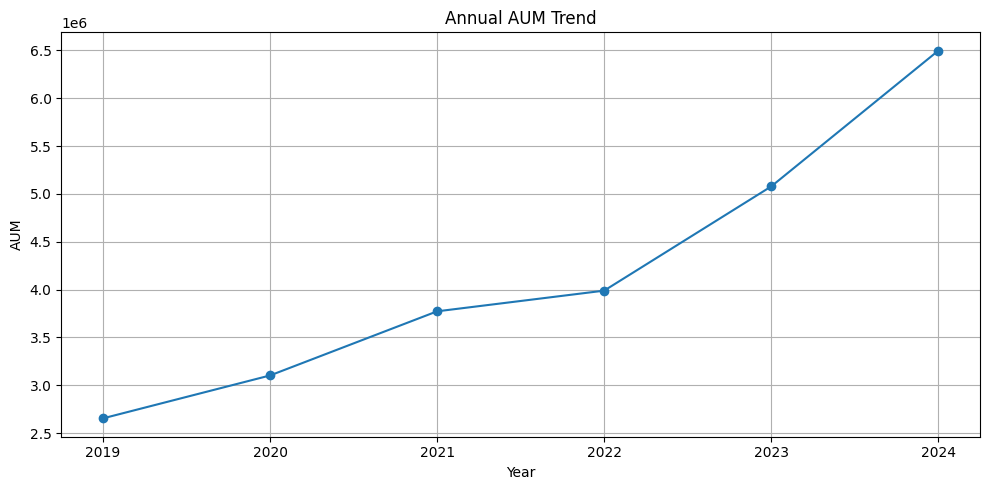

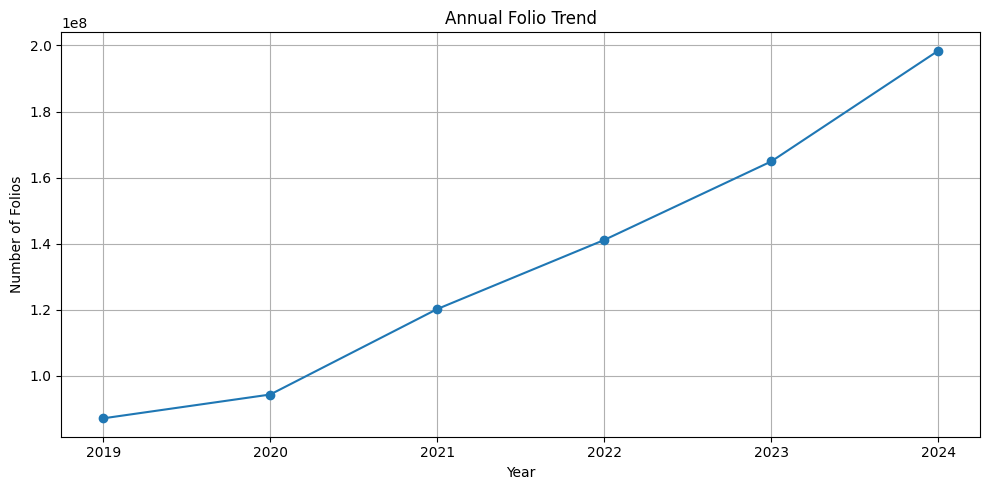

In [122]:
# Annual AUM Trend
plt.figure(figsize=(10, 5))
plt.plot(
    yearly_aum.index,
    yearly_aum.values,
    marker="o"
)

plt.title("Annual AUM Trend")
plt.xlabel("Year")
plt.ylabel("AUM")
plt.xticks(yearly_aum.index)
plt.grid(True)
plt.tight_layout()
plt.show()


# Annual Folio Trend
plt.figure(figsize=(10, 5))
plt.plot(
    yearly_folios.index,
    yearly_folios.values,
    marker="o"
)

plt.title("Annual Folio Trend")
plt.xlabel("Year")
plt.ylabel("Number of Folios")
plt.xticks(yearly_folios.index)
plt.grid(True)
plt.tight_layout()
plt.show()

Year-end AUM increased every year throughout the study period. Growth was relatively moderate in 2022 but accelerated significantly in 2023 and 2024. The highest annual growth was recorded in 2024 at 27.94%, while the lowest occurred in 2022 at 5.73%.


The number of investor folios increased continuously across the study period, reaching 198.41 million by July 2024. The strongest annual folio growth occurred in 2021 at 27.42%, while the lowest occurred in 2020 at 8.27%.

**Identify the Strongest and Weakest Annual Growth**

In [123]:
# Strongest and Weakest Annual Growth

print("ANNUAL GROWTH HIGHLIGHTS")
print("-" * 60)

# AUM growth
aum_growth = yearly_growth_summary["AUM_Change_Pct"].dropna()

print("\nAUM Percentage Growth:")
print(f"Highest growth: {aum_growth.idxmax()} ({aum_growth.max():.2f}%)")
print(f"Lowest growth: {aum_growth.idxmin()} ({aum_growth.min():.2f}%)")

# Folio growth
folio_growth = yearly_growth_summary["Folios_Change_Pct"].dropna()

print("\nFolio Percentage Growth:")
print(f"Highest growth: {folio_growth.idxmax()} ({folio_growth.max():.2f}%)")
print(f"Lowest growth: {folio_growth.idxmin()} ({folio_growth.min():.2f}%)")

ANNUAL GROWTH HIGHLIGHTS
------------------------------------------------------------

AUM Percentage Growth:
Highest growth: 2024 (27.94%)
Lowest growth: 2022 (5.73%)

Folio Percentage Growth:
Highest growth: 2021 (27.42%)
Lowest growth: 2020 (8.27%)


**Monthly Net Inflow/Outflow by Calendar Month**

In [124]:
# Average Net Flow by Calendar Month

monthly["calendar_month"] = monthly.index.month

month_names = {
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
}

average_flow_by_month = (
    monthly.groupby("calendar_month")["net_inflow_outflow"]
    .mean()
    .reindex(range(1, 13))
)

average_flow_by_month.index = [
    month_names[m] for m in average_flow_by_month.index
]

print("AVERAGE NET INFLOW/OUTFLOW BY CALENDAR MONTH")
print("-" * 60)
print(average_flow_by_month.round(2).to_string())

AVERAGE NET INFLOW/OUTFLOW BY CALENDAR MONTH
------------------------------------------------------------
January       50878.40
February      32312.81
March        -98203.44
April        112146.68
May           44934.38
June         -42123.38
July          97641.74
August        40084.96
September    -71746.88
October       72981.69
November      33331.54
December     -19849.42


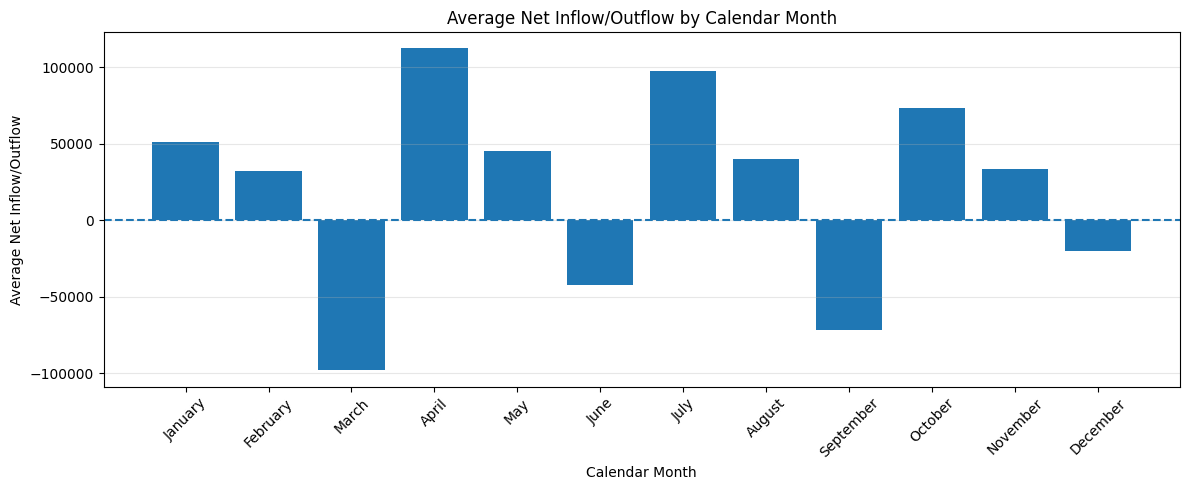

In [125]:
# Average Net Flow by Calendar Month

plt.figure(figsize=(12, 5))

plt.bar(
    average_flow_by_month.index,
    average_flow_by_month.values
)

plt.title("Average Net Inflow/Outflow by Calendar Month")
plt.xlabel("Calendar Month")
plt.ylabel("Average Net Inflow/Outflow")
plt.xticks(rotation=45)
plt.axhline(y=0, linestyle="--")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Average net flows varied noticeably by calendar month. April recorded the highest average net flow, while March recorded the lowest. March, June, September, and December had negative average flows, whereas most other months had positive average flows. This suggests recurring calendar-month patterns in the observed data, although the dataset is not sufficient to establish a causal seasonal effect.

**Identify the Best and Worst Months for Net Flow**

In [126]:
# Best and Worst Calendar Months for Net Flow

valid_months = average_flow_by_month.dropna()

print("BEST AND WORST CALENDAR MONTHS FOR NET FLOW")
print("-" * 60)

print(
    f"Highest average net flow: "
    f"{valid_months.idxmax()} ({valid_months.max():.2f})"
)

print(
    f"Lowest average net flow: "
    f"{valid_months.idxmin()} ({valid_months.min():.2f})"
)

BEST AND WORST CALENDAR MONTHS FOR NET FLOW
------------------------------------------------------------
Highest average net flow: April (112146.68)
Lowest average net flow: March (-98203.44)


**Analyze Positive vs. Negative Net Flow Months**

This step counts how many months recorded net inflows, net outflows, or zero net flow in the dataset.

In [127]:
# Count Positive, Negative, and Zero Net Flow Months

net_flow = monthly["net_inflow_outflow"]

positive_months = (net_flow > 0).sum()
negative_months = (net_flow < 0).sum()
zero_months = (net_flow == 0).sum()

print("POSITIVE VS. NEGATIVE NET FLOW MONTHS")
print("-" * 60)

print(f"Months with net inflows:  {positive_months}")
print(f"Months with net outflows: {negative_months}")
print(f"Months with zero net flow: {zero_months}")
print(f"Total months:             {len(net_flow)}")

POSITIVE VS. NEGATIVE NET FLOW MONTHS
------------------------------------------------------------
Months with net inflows:  42
Months with net outflows: 22
Months with zero net flow: 0
Total months:             64


**Calculate the Percentage of Positive and Negative Net Flow Months**

In [128]:
# Percentage of Positive, Negative, and Zero Net Flow Months

total_months = len(monthly)

positive_pct = (positive_months / total_months) * 100
negative_pct = (negative_months / total_months) * 100
zero_pct = (zero_months / total_months) * 100

print("NET FLOW MONTHLY DISTRIBUTION")
print("-" * 60)

print(f"Positive net flow months: {positive_pct:.2f}%")
print(f"Negative net flow months: {negative_pct:.2f}%")
print(f"Zero net flow months:     {zero_pct:.2f}%")
print(f"Total:                    {positive_pct + negative_pct + zero_pct:.2f}%")

NET FLOW MONTHLY DISTRIBUTION
------------------------------------------------------------
Positive net flow months: 65.62%
Negative net flow months: 34.38%
Zero net flow months:     0.00%
Total:                    100.00%


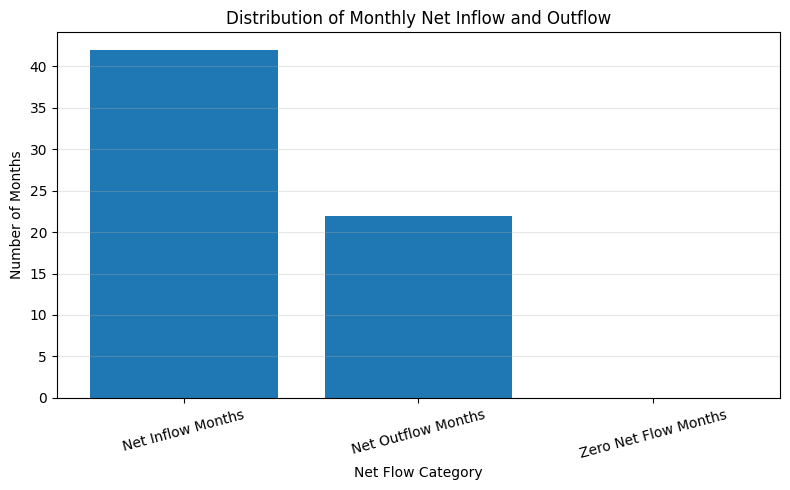

In [129]:
# Positive vs. Negative Net Flow Months

import matplotlib.pyplot as plt

categories = ["Net Inflow Months", "Net Outflow Months", "Zero Net Flow Months"]
counts = [positive_months, negative_months, zero_months]

plt.figure(figsize=(8, 5))
plt.bar(categories, counts)

plt.title("Distribution of Monthly Net Inflow and Outflow")
plt.xlabel("Net Flow Category")
plt.ylabel("Number of Months")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Positive net-flow months were more frequent than negative-flow months, with 65.62% of the observed months recording net inflows. However, the presence of 22 negative-flow months shows that outflows were also a recurring feature of the industry during the study period.

**Analyze the Relationship Between Folio Growth and Net Flow**

This checks whether monthly changes in the number of folios move together with net inflows/outflows. It calculates their correlation using the change in folios rather than the total folio count.

In [130]:
# Correlation Between Folio Growth and Net Flow

folio_flow_data = monthly[
    ["folios_change", "net_inflow_outflow"]
].dropna()

folio_flow_correlation = folio_flow_data[
    "folios_change"
].corr(folio_flow_data["net_inflow_outflow"])

print("FOLIO GROWTH AND NET FLOW CORRELATION")
print("-" * 60)
print(f"Correlation coefficient: {folio_flow_correlation:.4f}")

FOLIO GROWTH AND NET FLOW CORRELATION
------------------------------------------------------------
Correlation coefficient: 0.2096


Correlation coefficient is 0.2096, indicating a weak positive relationship between monthly folio growth and net inflow/outflow.
This means months with higher folio growth tended to have somewhat higher net flows, but the relationship is weak. It does not establish causation.

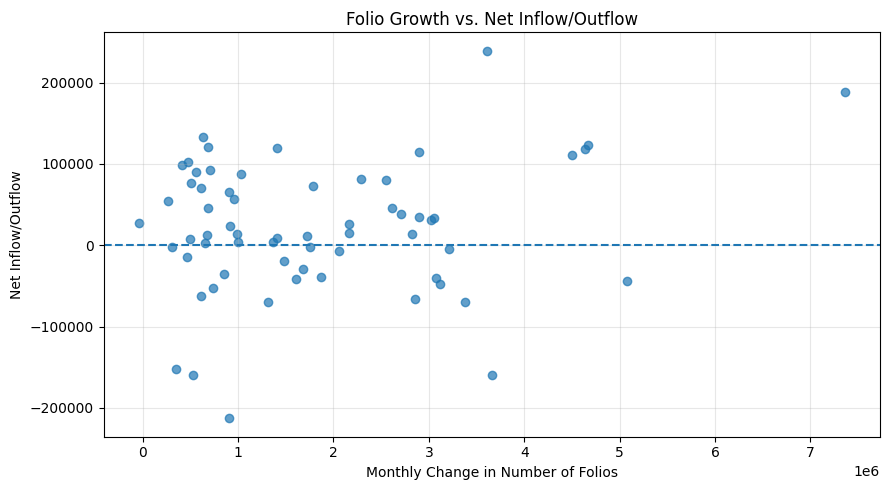

In [131]:
# Folio Growth vs. Net Flow Scatter Plot

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.scatter(
    monthly["folios_change"],
    monthly["net_inflow_outflow"],
    alpha=0.7
)

plt.title("Folio Growth vs. Net Inflow/Outflow")
plt.xlabel("Monthly Change in Number of Folios")
plt.ylabel("Net Inflow/Outflow")
plt.axhline(y=0, linestyle="--")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Folio growth and net flows show a weak positive relationship with a correlation of 0.2096. This suggests that increases in investor folios were associated with higher net flows to some extent, but folio growth alone does not strongly explain monthly changes in net flows.

**Check the Relationship Between AUM Growth and Folio Growth**

This checks whether monthly changes in Assets Under Management (AUM) and the number of folios move together.

In [132]:
# Correlation Between AUM Growth and Folio Growth

growth_data = monthly[
    ["aum_change", "folios_change"]
].dropna()

growth_correlation = growth_data["aum_change"].corr(
    growth_data["folios_change"]
)

print("AUM GROWTH AND FOLIO GROWTH CORRELATION")
print("-" * 60)
print(f"Correlation coefficient: {growth_correlation:.4f}")

AUM GROWTH AND FOLIO GROWTH CORRELATION
------------------------------------------------------------
Correlation coefficient: 0.3097


Correlation coefficient is 0.3097, indicating a weak positive relationship between monthly AUM growth and folio growth.
This suggests that months with larger increases in folios tended to coincide somewhat with increases in AUM, but the relationship is not strong.

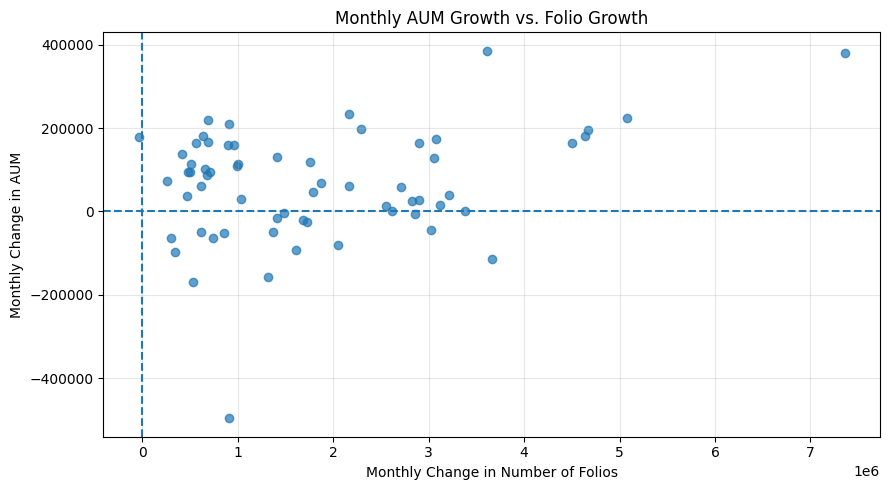

In [133]:
# AUM Growth vs. Folio Growth Scatter Plot

plt.figure(figsize=(9, 5))

plt.scatter(
    monthly["folios_change"],
    monthly["aum_change"],
    alpha=0.7
)

plt.title("Monthly AUM Growth vs. Folio Growth")
plt.xlabel("Monthly Change in Number of Folios")
plt.ylabel("Monthly Change in AUM")
plt.axhline(y=0, linestyle="--")
plt.axvline(x=0, linestyle="--")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Monthly AUM growth and folio growth have a weak positive relationship with a correlation of 0.3097. This indicates that months with increasing folio counts tended to coincide somewhat with increasing AUM, but the relationship was not strong enough to suggest that folio growth alone explains AUM changes.

**Analyze Monthly Net Flow Volatility**


This calculates the standard deviation of monthly net inflow/outflow and compares it with the average net flow. It helps quantify how much net flows fluctuate over time.

In [134]:
# Monthly Net Flow Volatility

net_flow = monthly["net_inflow_outflow"]

net_flow_mean = net_flow.mean()
net_flow_std = net_flow.std()
net_flow_cv = (net_flow_std / abs(net_flow_mean)) * 100

print("MONTHLY NET FLOW VOLATILITY")
print("-" * 60)
print(f"Average monthly net flow: {net_flow_mean:.2f}")
print(f"Standard deviation:       {net_flow_std:.2f}")
print(f"Coefficient of variation: {net_flow_cv:.2f}%")

MONTHLY NET FLOW VOLATILITY
------------------------------------------------------------
Average monthly net flow: 23039.76
Standard deviation:       81540.08
Coefficient of variation: 353.91%


The standard deviation is much larger than the average net flow, indicating considerable variation in monthly flows. The coefficient of variation is high, but interpret it cautiously because net flows can be positive or negative and the mean is relatively small compared with the fluctuations.

**Identify the Most Volatile Months**

Identify the five months with the largest absolute net inflows or outflows. This helps pinpoint the months with the most extreme movements.

In [135]:
# Top 5 Months by Absolute Net Flow

monthly["absolute_net_flow"] = (
    monthly["net_inflow_outflow"].abs()
)

top_5_volatile_months = monthly.nlargest(
    5, "absolute_net_flow"
)[["net_inflow_outflow", "absolute_net_flow"]]

print("TOP 5 MONTHS WITH THE LARGEST NET FLOW MOVEMENTS")
print("-" * 70)
print(top_5_volatile_months.round(2).to_string())

TOP 5 MONTHS WITH THE LARGEST NET FLOW MOVEMENTS
----------------------------------------------------------------------
            net_inflow_outflow  absolute_net_flow
date                                             
2024-04-01           239232.85          239232.85
2020-03-01          -212737.09          212737.09
2024-07-01           189043.72          189043.72
2019-06-01          -159814.38          159814.38
2024-03-01          -159387.13          159387.13


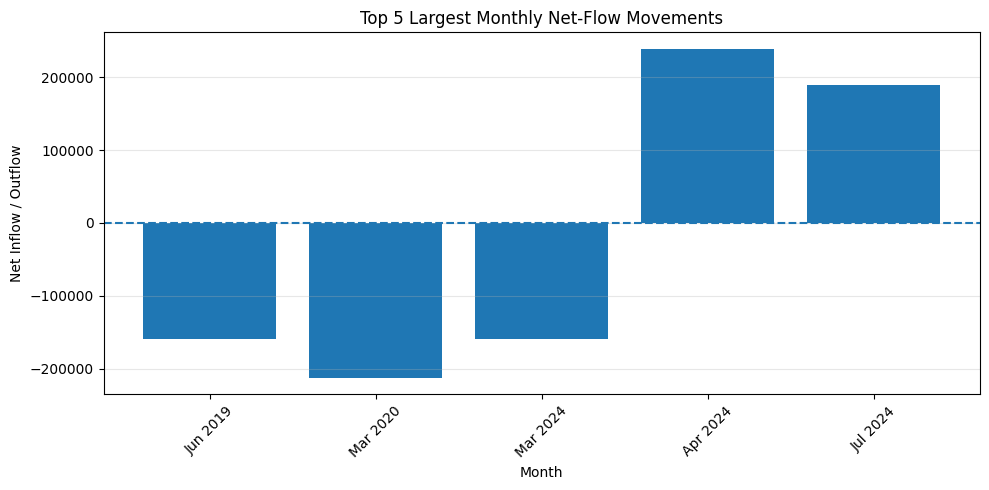

In [136]:
# Visualize Top 5 Net-Flow Movements

import matplotlib.pyplot as plt

top_5_flows = top_5_volatile_months.sort_index()

plt.figure(figsize=(10, 5))

plt.bar(
    top_5_flows.index.strftime("%b %Y"),
    top_5_flows["net_inflow_outflow"]
)

plt.title("Top 5 Largest Monthly Net-Flow Movements")
plt.xlabel("Month")
plt.ylabel("Net Inflow / Outflow")
plt.axhline(y=0, linestyle="--")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

The largest monthly net-flow movements were concentrated in a small number of periods, demonstrating that aggregate monthly flows can change sharply. The strongest positive movement occurred in April 2024, while the strongest negative movement occurred in March 2020.

**Compare Inflow Volatility with Outflow Volatility**

This calculates the average and standard deviation separately for months with positive and negative net flows.

In [137]:
# Compare Inflow and Outflow Volatility

inflow_months = monthly.loc[
    monthly["net_inflow_outflow"] > 0, "net_inflow_outflow"
]

outflow_months = monthly.loc[
    monthly["net_inflow_outflow"] < 0, "net_inflow_outflow"
]

print("INFLOW VS OUTFLOW ANALYSIS")
print("-" * 60)

print("\nPositive Net Flow Months:")
print(f"Count: {len(inflow_months)}")
print(f"Average: {inflow_months.mean():.2f}")
print(f"Standard deviation: {inflow_months.std():.2f}")

print("\nNegative Net Flow Months:")
print(f"Count: {len(outflow_months)}")
print(f"Average: {outflow_months.mean():.2f}")
print(f"Standard deviation: {outflow_months.std():.2f}")

INFLOW VS OUTFLOW ANALYSIS
------------------------------------------------------------

Positive Net Flow Months:
Count: 42
Average: 66775.92
Standard deviation: 52691.78

Negative Net Flow Months:
Count: 22
Average: -60456.54
Standard deviation: 58278.64


**Analyze the Distribution of Monthly Net Flows**

Let's calculate the median, skewness, and kurtosis to understand the distribution of monthly net flows and whether extreme values may influence it.

In [138]:
# Net Flow Distribution Analysis

net_flow = monthly["net_inflow_outflow"]

print("NET FLOW DISTRIBUTION ANALYSIS")
print("-" * 60)

print(f"Mean:     {net_flow.mean():.2f}")
print(f"Median:   {net_flow.median():.2f}")
print(f"Skewness: {net_flow.skew():.4f}")
print(f"Kurtosis: {net_flow.kurt():.4f}")

NET FLOW DISTRIBUTION ANALYSIS
------------------------------------------------------------
Mean:     23039.76
Median:   19462.60
Skewness: -0.3483
Kurtosis: 0.9870


The results show a mean of 23,039.76 and a median of 19,462.60. The negative skewness (−0.3483) indicates a mildly longer tail toward negative net flows, while the positive excess kurtosis (0.9870) suggests heavier tails than a normal distribution.

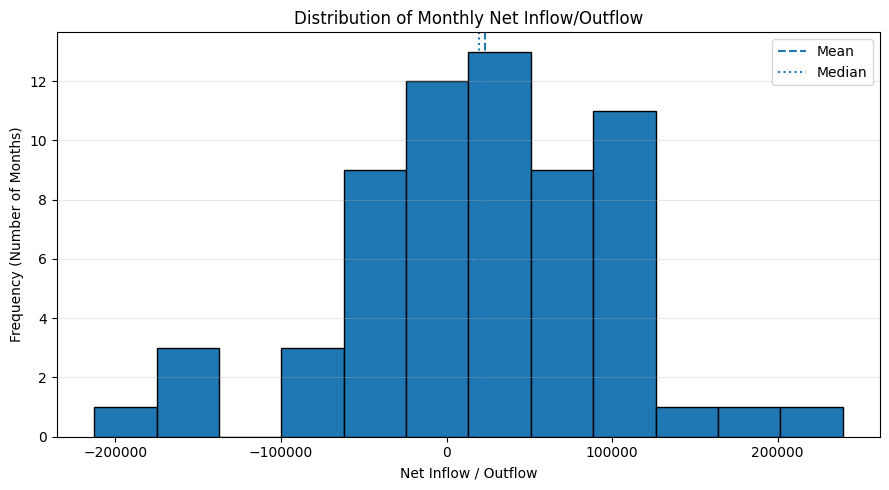

In [139]:
# Histogram of Monthly Net Flows

plt.figure(figsize=(9, 5))

plt.hist(
    monthly["net_inflow_outflow"],
    bins=12,
    edgecolor="black"
)

plt.title("Distribution of Monthly Net Inflow/Outflow")
plt.xlabel("Net Inflow / Outflow")
plt.ylabel("Frequency (Number of Months)")
plt.axvline(
    monthly["net_inflow_outflow"].mean(),
    linestyle="--",
    label="Mean"
)
plt.axvline(
    monthly["net_inflow_outflow"].median(),
    linestyle=":",
    label="Median"
)

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Monthly net flows were widely dispersed, with the standard deviation substantially exceeding the mean. The mean was moderately higher than the median, indicating that large positive and negative movements influenced the distribution. Overall, the distribution reflects considerable month-to-month variability.

**Compare Mean and Median Net Flows**


This checks how far the mean is from the median and expresses the difference as a percentage of the median. It helps quantify how much the average is influenced by unusually large monthly movements.

In [140]:
# Mean vs Median Net Flow

net_flow_mean = monthly["net_inflow_outflow"].mean()
net_flow_median = monthly["net_inflow_outflow"].median()

difference = net_flow_mean - net_flow_median
difference_pct = (difference / abs(net_flow_median)) * 100

print("MEAN VS MEDIAN NET FLOW")
print("-" * 60)
print(f"Mean:                 {net_flow_mean:.2f}")
print(f"Median:               {net_flow_median:.2f}")
print(f"Mean - Median:        {difference:.2f}")
print(f"Difference (% median): {difference_pct:.2f}%")

MEAN VS MEDIAN NET FLOW
------------------------------------------------------------
Mean:                 23039.76
Median:               19462.60
Mean - Median:        3577.16
Difference (% median): 18.38%


Mean is 18.38% higher than the median, suggesting that larger positive monthly flows may be pulling the average upward.

**Analyze Monthly AUM Volatility**


Now let's measure how much monthly changes in AUM fluctuate. We'll calculate the average monthly AUM change, its standard deviation, and the coefficient of variation.

In [141]:
# Monthly AUM Volatility

aum_change = monthly["aum_change"].dropna()

aum_change_mean = aum_change.mean()
aum_change_std = aum_change.std()

print("MONTHLY AUM VOLATILITY")
print("-" * 60)
print(f"Average monthly AUM change: {aum_change_mean:.2f}")
print(f"Standard deviation:         {aum_change_std:.2f}")

if abs(aum_change_mean) > 0:
    aum_change_cv = (aum_change_std / abs(aum_change_mean)) * 100
    print(f"Coefficient of variation:   {aum_change_cv:.2f}%")
else:
    print("Coefficient of variation: Undefined (mean is zero)")

MONTHLY AUM VOLATILITY
------------------------------------------------------------
Average monthly AUM change: 63776.13
Standard deviation:         135244.03
Coefficient of variation:   212.06%


**Identify the Largest Monthly AUM Increases and Decreases**

In [142]:
# Largest Monthly AUM Increases and Decreases

aum_changes = monthly["aum_change"].dropna()

top_5_aum_increases = aum_changes.nlargest(5)
top_5_aum_decreases = aum_changes.nsmallest(5)

print("TOP 5 MONTHLY AUM INCREASES")
print("-" * 60)
print(top_5_aum_increases.round(2).to_string())

print("\nTOP 5 MONTHLY AUM DECREASES")
print("-" * 60)
print(top_5_aum_decreases.round(2).to_string())

TOP 5 MONTHLY AUM INCREASES
------------------------------------------------------------
date
2024-04-01    385703.32
2024-07-01    381071.23
2023-11-01    233304.51
2024-06-01    224421.44
2023-04-01    219790.94

TOP 5 MONTHLY AUM DECREASES
------------------------------------------------------------
date
2020-03-01   -496734.47
2019-06-01   -168519.23
2022-06-01   -157919.97
2024-03-01   -114019.53
2019-09-01    -96807.02


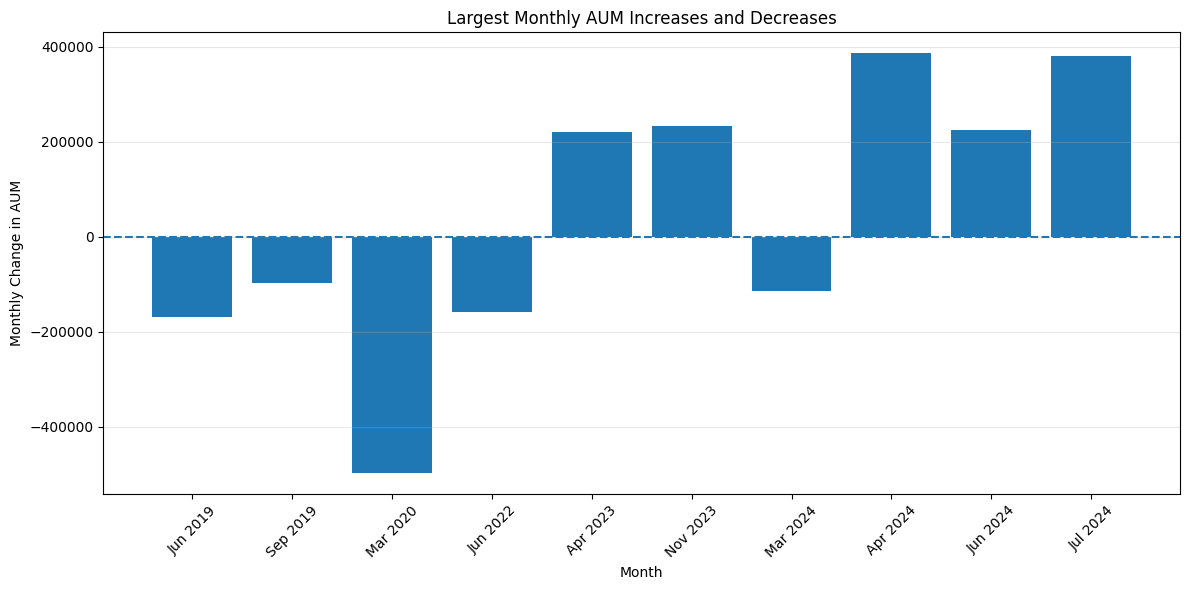

In [143]:
# Visualize Largest Monthly AUM Changes

extreme_aum_changes = pd.concat([
    top_5_aum_increases,
    top_5_aum_decreases
]).sort_index()

plt.figure(figsize=(12, 6))

plt.bar(
    extreme_aum_changes.index.strftime("%b %Y"),
    extreme_aum_changes.values
)

plt.title("Largest Monthly AUM Increases and Decreases")
plt.xlabel("Month")
plt.ylabel("Monthly Change in AUM")
plt.axhline(y=0, linestyle="--")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

AUM experienced several sharp monthly movements, with March 2020 recording the largest decline and April 2024 recording the largest increase. The concentration of extreme movements in a limited number of months highlights the importance of examining monthly volatility rather than relying only on long-term growth figures.

**Compare AUM Growth with Net Inflow/Outflow**


Now let's calculate the difference between monthly AUM change and monthly net flow. This helps quantify how much the change in AUM differs from the recorded net inflow/outflow.

In [144]:
# AUM Change vs Net Flow Difference

difference_data = monthly["aum_change_minus_net_flow"].dropna()

print("AUM CHANGE MINUS NET FLOW")
print("-" * 60)
print(f"Average difference: {difference_data.mean():.2f}")
print(f"Median difference:  {difference_data.median():.2f}")
print(f"Minimum difference: {difference_data.min():.2f}")
print(f"Maximum difference: {difference_data.max():.2f}")
print(f"Standard deviation: {difference_data.std():.2f}")

AUM CHANGE MINUS NET FLOW
------------------------------------------------------------
Average difference: 41965.26
Median difference:  45896.28
Minimum difference: -283997.38
Maximum difference: 268057.99
Standard deviation: 87467.11


**Analyze Monthly Folio Growth Volatility**

In [145]:
# Monthly Folio Growth Volatility

folio_change = monthly["folios_change"].dropna()

folio_change_mean = folio_change.mean()
folio_change_std = folio_change.std()

print("MONTHLY FOLIO GROWTH VOLATILITY")
print("-" * 60)
print(f"Average monthly folio change: {folio_change_mean:.2f}")
print(f"Standard deviation:           {folio_change_std:.2f}")

if abs(folio_change_mean) > 0:
    folio_change_cv = (
        folio_change_std / abs(folio_change_mean)
    ) * 100
    print(f"Coefficient of variation:     {folio_change_cv:.2f}%")
else:
    print("Coefficient of variation: Undefined (mean is zero)")

MONTHLY FOLIO GROWTH VOLATILITY
------------------------------------------------------------
Average monthly folio change: 1836031.03
Standard deviation:           1450436.19
Coefficient of variation:     79.00%


**Identify the Largest Monthly Folio Increases and Decreases**

In [146]:
# Largest Monthly Folio Increases and Decreases

folio_changes = monthly["folios_change"].dropna()

top_5_folio_increases = folio_changes.nlargest(5)
top_5_folio_decreases = folio_changes.nsmallest(5)

print("TOP 5 MONTHLY FOLIO INCREASES")
print("-" * 60)
print(top_5_folio_increases.round(0).to_string())

print("\nTOP 5 MONTHLY FOLIO DECREASES")
print("-" * 60)
print(top_5_folio_decreases.round(0).to_string())

TOP 5 MONTHLY FOLIO INCREASES
------------------------------------------------------------
date
2024-07-01    7359176.0
2024-06-01    5078896.0
2024-01-01    4668910.0
2024-02-01    4636353.0
2024-05-01    4499936.0

TOP 5 MONTHLY FOLIO DECREASES
------------------------------------------------------------
date
2020-11-01    -39658.0
2019-11-01    261705.0
2020-02-01    303008.0
2019-09-01    345022.0
2020-10-01    411511.0


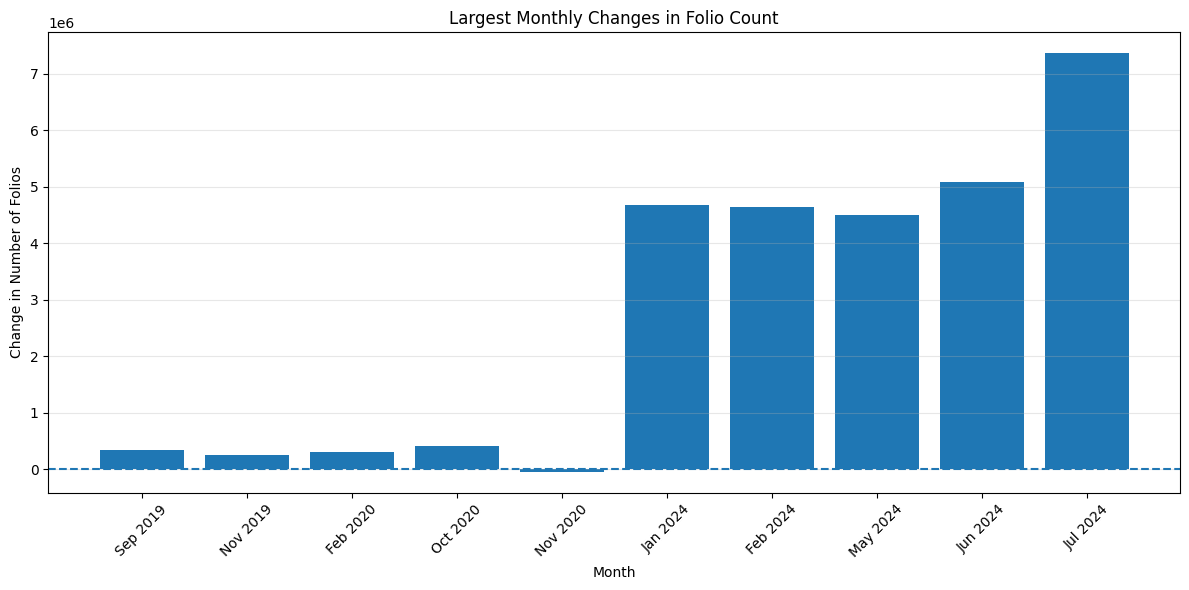

In [147]:
# Visualize Largest Monthly Folio Changes

extreme_folio_changes = pd.concat([
    top_5_folio_increases,
    top_5_folio_decreases
])

# Remove duplicate months and retain unique observations
extreme_folio_changes = extreme_folio_changes[
    ~extreme_folio_changes.index.duplicated(keep="first")
].sort_index()

plt.figure(figsize=(12, 6))

plt.bar(
    extreme_folio_changes.index.strftime("%b %Y"),
    extreme_folio_changes.values
)

plt.title("Largest Monthly Changes in Folio Count")
plt.xlabel("Month")
plt.ylabel("Change in Number of Folios")
plt.axhline(y=0, linestyle="--")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Folio growth was particularly strong during 2024, with the largest increases concentrated between January and July. In contrast, the largest decline was relatively small, occurring in November 2020. This suggests that investor participation showed a stronger and more consistent upward pattern than AUM.

**Calculate the Overall Folio Growth**

Now let's calculate the total change in folios across your dataset, from the first available month to the latest available month, and the overall percentage growth.

In [148]:
# Overall Folio Growth

first_folios = monthly["no_of_folios"].iloc[0]
last_folios = monthly["no_of_folios"].iloc[-1]

total_folio_change = last_folios - first_folios

total_folio_growth_pct = (
    (last_folios - first_folios) / first_folios
) * 100

print("OVERALL FOLIO GROWTH")
print("-" * 60)
print(f"First month folios:       {first_folios:,.0f}")
print(f"Latest month folios:      {last_folios:,.0f}")
print(f"Total folio change:       {total_folio_change:,.0f}")
print(f"Overall growth:           {total_folio_growth_pct:.2f}%")
print(f"Period:                   {monthly.index[0]:%b %Y} to {monthly.index[-1]:%b %Y}")

OVERALL FOLIO GROWTH
------------------------------------------------------------
First month folios:       82,736,339
Latest month folios:      198,406,294
Total folio change:       115,669,955
Overall growth:           139.81%
Period:                   Apr 2019 to Jul 2024


**Calculate Overall AUM Growth**

In [149]:
# Overall AUM Growth

first_aum = monthly["net_aum"].iloc[0]
last_aum = monthly["net_aum"].iloc[-1]

total_aum_change = last_aum - first_aum

total_aum_growth_pct = (
    (last_aum - first_aum) / first_aum
) * 100

print("OVERALL AUM GROWTH")
print("-" * 60)
print(f"First month AUM:      {first_aum:,.2f}")
print(f"Latest month AUM:     {last_aum:,.2f}")
print(f"Total AUM change:     {total_aum_change:,.2f}")
print(f"Overall AUM growth:   {total_aum_growth_pct:.2f}%")
print(
    f"Period:               "
    f"{monthly.index[0]:%b %Y} to {monthly.index[-1]:%b %Y}"
)

OVERALL AUM GROWTH
------------------------------------------------------------
First month AUM:      2,478,756.91
Latest month AUM:     6,496,653.14
Total AUM change:     4,017,896.23
Overall AUM growth:   162.09%
Period:               Apr 2019 to Jul 2024


**Compare Overall AUM Growth vs Folio Growth**

In [150]:
# Compare Overall AUM Growth and Folio Growth

first_aum = monthly["net_aum"].iloc[0]
last_aum = monthly["net_aum"].iloc[-1]

first_folios = monthly["no_of_folios"].iloc[0]
last_folios = monthly["no_of_folios"].iloc[-1]

aum_growth_pct = ((last_aum - first_aum) / first_aum) * 100

folio_growth_pct = (
    (last_folios - first_folios) / first_folios
) * 100

growth_difference = aum_growth_pct - folio_growth_pct

print("OVERALL AUM GROWTH VS FOLIO GROWTH")
print("-" * 60)
print(f"AUM growth:             {aum_growth_pct:.2f}%")
print(f"Folio growth:           {folio_growth_pct:.2f}%")
print(f"Growth difference:      {growth_difference:.2f} percentage points")

if growth_difference > 0:
    print("Result: AUM grew faster than folios.")
elif growth_difference < 0:
    print("Result: Folios grew faster than AUM.")
else:
    print("Result: AUM and folios grew at the same rate.")

OVERALL AUM GROWTH VS FOLIO GROWTH
------------------------------------------------------------
AUM growth:             162.09%
Folio growth:           139.81%
Growth difference:      22.29 percentage points
Result: AUM grew faster than folios.


Net flows exhibited the highest relative volatility, followed by AUM changes, while folio growth was comparatively more stable. This indicates that investor money flows were considerably more volatile than changes in investor participation.

## **Key Findings**


1. **Strong AUM growth:** Total net AUM increased by **162.09%**, rising from April 2019 to July 2024. The strongest annual AUM growth occurred in **2024 (27.94%)**, followed closely by **2023 (27.34%)**.


2. **Significant investor growth:** The total number of investor folios increased by **139.81%** over the same period, indicating substantial growth in investor participation. Folio growth was particularly strong in **2021 (27.42%)** and **2024 (20.33%)**.


3. **Positive net-flow pattern:** Out of 64 monthly observations, **42 months (65.62%) recorded positive net flows**, while **22 months (34.38%) recorded negative net flows**. This indicates that positive-flow months were more frequent than negative-flow months.


4. **Variation in annual net flows:** **2022 recorded the weakest annual net flow**, while **2024 recorded the highest total net flow among the periods analyzed**. However, 2024 includes only **January to July**, so its total should not be directly compared with complete calendar years.


5. **Strong relationship between AUM change and net flows:** Monthly AUM change showed a **strong positive correlation with monthly net flows (0.784)**, indicating that periods with higher net inflows generally coincided with larger increases in AUM. This represents an association and does not establish causation.


6. **Weak relationships involving folio growth:** Folio growth showed a **weak positive correlation with net flows (0.2096)**, while AUM growth and folio growth also showed a **weak positive correlation (0.3097)**. This suggests that changes in investor participation were related to, but did not strongly explain, monthly changes in flows or AUM.


7. **High month-to-month volatility:** Net flows and AUM experienced substantial monthly fluctuations. The largest monthly decline in AUM occurred in **March 2020 (-18.24%)**, while the largest increase occurred in **April 2020 (+7.51%)**. Net flows also ranged from a sharp outflow in **March 2020 (-212,737.09)** to the highest inflow in **April 2024 (+239,232.85)**.


8. **Category-level fund activity:** **Income/Debt Oriented Schemes** recorded the highest fund mobilization and repurchase/redemption activity among the analyzed categories. Fund mobilization remained slightly higher than repurchase/redemption across all categories.


9. **Anomaly detection:** The financial anomaly analysis identified **3 potentially unusual records out of 3,115 scheme-level records**. These observations should be treated as unusual patterns requiring further investigation rather than being interpreted as errors or fraud without additional evidence.


10. **Overall industry trend:** Despite periods of significant volatility and negative net flows, the overall analysis shows a **strong upward trend in AUM and investor folios** between April 2019 and July 2024, indicating substantial expansion of the mutual fund industry's assets and investor participation during the study period.